# ABC Retail Revenue Prediction Model

## Executive summary

**Task:** build a model to predict ABC-Retail's reported `revenue_index` from order-number and transaction-panel data; train on reported periods up to 2022 Q3 and evaluate on 2022 Q4.

**Chosen model:** linear regression of revenue on **panel-adjusted spend** (daily panel spend ÷ weekly active users, summed over each reporting period):
`revenue_index ≈ 4.34 + 3.617 × spend_adj`

| Metric | Result |
|---|---|
| **In-sample R²** (19 training periods) | **0.945** (adjusted 0.942) |
| **2022 Q4 prediction (out of sample)** | **485.7** vs actual **512.1** → **−5.1%** (under-prediction) |
| 80% / 95% prediction interval for 2022 Q4 | 440 – 531 / 414 – 558 (actual inside both) |
| Walk-forward backtest error (6 periods, 2021 Q2 – 2022 Q3) | **6.55%** vs 11.90% for a naive "last year's rate" benchmark and 15.45% for SARIMA |
| Direction vs 2021 Q4 | Predicted −12.1%, actual −7.3%: decline called correctly |

**Key points**
- **Raw panel spend is misleading:** the panel grew 22× while revenue grew 1.8×. Normalising by active users was essential (correlation with revenue 0.81 → 0.97).
- **Order numbers needed heavy cleaning:** 211 impossible decreases, near-zero and stale values. A layered cleaning (gross errors → asymmetric trend filter → monotonicity) raised agreement with the panel's independent order counts from **0.08 to 0.92**.
- **Model chosen on a walk-forward backtest, not the test period.** 2022 Q4 was used once, after selection.

## How to run

1. Put `data_task.xlsx` in the same folder as this notebook (or, in Google Colab, in `MyDrive/`).
2. Install the requirements: `pip install pandas numpy matplotlib statsmodels openpyxl`
3. Run all cells from top to bottom (**Runtime → Run all** in Colab; **Kernel → Restart & Run All** in Jupyter).

Tested with Python 3.10+, pandas 2.x and statsmodels 0.14.

In [746]:
# All imports used in this notebook
import warnings
from bisect import bisect_left
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.width", 160)

# Stage 1: Exploratory Data Analysis

## Loading and First Look

In [747]:
# Load the data. Works locally (file next to the notebook) or in Colab (file in Google Drive)

DATA_FILE = Path("data_task.xlsx")                      # default: same folder as this notebook
if not DATA_FILE.exists():
    try:
        from google.colab import drive                  # only available inside Google Colab
        drive.mount("/content/drive")
        DATA_FILE = Path("/content/drive/MyDrive/data_task.xlsx")
    except ImportError:
        raise FileNotFoundError("Place data_task.xlsx in the same folder as this notebook.")

sheets = pd.read_excel(DATA_FILE, sheet_name=None)      # dictionary: {sheet name: DataFrame}
print("Loaded:", DATA_FILE, "| sheets:", list(sheets.keys()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: /content/drive/MyDrive/data_task.xlsx | sheets: ['order_numbers', 'transaction_data', 'reported_data']


In [748]:
# Assign each sheet to its own variable
orders   = sheets["order_numbers"]
txn      = sheets["transaction_data"]
reported = sheets["reported_data"]

In [749]:
# Shape, data types and first rows of each sheet
for name, d in [("orders", orders), ("txn", txn), ("reported", reported)]:
    print(f"===== {name} =====")
    print("Shape:", d.shape)
    print(d.dtypes)
    display(d.head())

===== orders =====
Shape: (856, 2)
date            datetime64[ns]
order_number             int64
dtype: object


,date,order_number
0,2018-01-07,33841906
1,2018-01-22,34008921
2,2018-01-25,34397468
3,2018-02-06,34434432
4,2018-02-08,34579365


===== txn =====
Shape: (1826, 4)
date                         datetime64[ns]
total_spend_index                   float64
gross_orders_index                  float64
weekly_active_users_index           float64
dtype: object


,date,total_spend_index,gross_orders_index,weekly_active_users_index
0,2018-01-01,0.052537,0.158983,1.563652
1,2018-01-02,0.839176,1.430843,1.628314
2,2018-01-03,0.182855,0.476948,1.633740
3,2018-01-04,2.364675,1.907790,1.657706
4,2018-01-05,0.687484,1.271860,1.679863


===== reported =====
Shape: (20, 4)
period                   object
start_date       datetime64[ns]
end_date         datetime64[ns]
revenue_index           float64
dtype: object


,period,start_date,end_date,revenue_index
0,2018 Q1,2018-01-01,2018-02-28,100.000000
1,2018 Q2,2018-03-01,2018-06-30,253.521127
2,2018 Q3,2018-07-01,2018-08-31,139.788732
3,2018 Q4,2018-09-01,2018-12-31,306.161972
4,2019 Q1,2019-01-01,2019-02-28,117.693662


Observation: the values in the date column are real dates and rest of the datatypes looks fine

In [750]:
# Make sure the date columns are real dates (they already are; this guarantees it)
orders["date"] = pd.to_datetime(orders["date"])
txn["date"] = pd.to_datetime(txn["date"])
reported["start_date"] = pd.to_datetime(reported["start_date"])
reported["end_date"] = pd.to_datetime(reported["end_date"])

In [751]:
# Are the dates in ascending order?
print("orders sorted by date:", orders["date"].is_monotonic_increasing)
print("txn sorted by date:", txn["date"].is_monotonic_increasing)

orders sorted by date: True
txn sorted by date: True


In [752]:
# Sort by date (and by value within a date) so row-to-row checks are reliable
orders = orders.sort_values(["date", "order_number"]).reset_index(drop=True)
txn = txn.sort_values("date").reset_index(drop=True)

**Observation:** both `orders` and `txn` are already in ascending date order. They are sorted anyway (orders by date, then by value within a date), so that every later row-to-row check (decreases, gaps) is reliable regardless of how the file was saved.

## Reported Period Analysis

In [753]:
# Period length (days, inclusive) and revenue per day
reported["days"] = (reported["end_date"] - reported["start_date"]).dt.days + 1
reported["rev_per_day"] = reported["revenue_index"] / reported["days"]
reported.head()

,period,start_date,end_date,revenue_index,days,rev_per_day
0,2018 Q1,2018-01-01,2018-02-28,100.000000,59,1.694915
1,2018 Q2,2018-03-01,2018-06-30,253.521127,122,2.078042
2,2018 Q3,2018-07-01,2018-08-31,139.788732,62,2.254657
3,2018 Q4,2018-09-01,2018-12-31,306.161972,122,2.509524
4,2019 Q1,2019-01-01,2019-02-28,117.693662,59,1.994808


In [754]:
# Are all periods the same length? Shortest and longest?
print(reported["days"].describe())
print("Shortest:", reported["days"].min(), "days")
print("Longest:", reported["days"].max(), "days")
print(reported["days"].value_counts())

count     20.000000
mean      91.300000
std       29.973848
min       59.000000
25%       61.500000
50%       92.000000
75%      122.000000
max      122.000000
Name: days, dtype: float64
Shortest: 59 days
Longest: 122 days
days
122    9
59     4
62     4
92     2
60     1
Name: count, dtype: int64


Observation:
*   9 periods are 122 days long
*   4 periods are 59 days long
*   4 periods are 62 days long
*   2 periods are 92 days long
*   1 period is 60 days long

In [755]:
# Which periods are 122 days long?
reported[reported["days"] == 122][["period", "start_date", "end_date"]]

,period,start_date,end_date
1,2018 Q2,2018-03-01,2018-06-30
3,2018 Q4,2018-09-01,2018-12-31
5,2019 Q2,2019-03-01,2019-06-30
7,2019 Q4,2019-09-01,2019-12-31
9,2020 Q2,2020-03-01,2020-06-30
11,2020 Q4,2020-09-01,2020-12-31
13,2021 Q2,2021-03-01,2021-06-30
15,2021 Q4,2021-09-01,2021-12-31
19,2022 Q4,2022-09-01,2022-12-31


In [756]:
# Which months does each period cover?
reported["start_month"] = reported["start_date"].dt.strftime("%b")   # e.g. "Jan"
reported["end_month"]   = reported["end_date"].dt.strftime("%b")
reported[["period", "start_month", "end_month", "days"]]

,period,start_month,end_month,days
0,2018 Q1,Jan,Feb,59
1,2018 Q2,Mar,Jun,122
2,2018 Q3,Jul,Aug,62
3,2018 Q4,Sep,Dec,122
4,2019 Q1,Jan,Feb,59
5,2019 Q2,Mar,Jun,122
6,2019 Q3,Jul,Aug,62
7,2019 Q4,Sep,Dec,122
8,2020 Q1,Jan,Feb,60
9,2020 Q2,Mar,Jun,122


In [757]:
# Period lengths as a years × quarters grid
reported["quarter"] = reported["period"].str[-2:]    # last two characters
reported["year"]    = reported["period"].str[:4]     # first four characters

reported.pivot(index="year", columns="quarter", values="days")

quarter,Q1,Q2,Q3,Q4
year,,,,
2018,59,122,62,122
2019,59,122,62,122
2020,60,122,62,122
2021,59,122,62,122
2022,59,92,92,122


### Observation: Reporting Periods

**What each period covers**

| Period | 2018 – 2021 | 2022 |
|---|---|---|
| Q1 | Jan – Feb | Jan – Feb |
| Q2 | Mar – Jun | Mar – May |
| Q3 | Jul – Aug | Jun – Aug |
| Q4 | Sep – Dec | Sep – Dec |

The periods do **not** match calendar quarters. They alternate between ~2-month and ~4-month periods.

**Period lengths and exceptions**

- **Q1:** 59 days in every year except **2020 (60 days)**, because 2020 was a leap year (29 February).
- **Q2:** 122 days in every year except **2022 (92 days)**, because June moved from Q2 to Q3.
- **Q3:** 62 days in every year except **2022 (92 days)**, because it gained June.
- **Q4:** 122 days in every year, with no exceptions.

**Consequence for the model:** 2022 Q2 and Q3 cover different months from earlier years, so they can't be compared directly with the same "quarter" in previous years. Features must be built from each period's exact start and end dates, not from the quarter labels.





## Revenue Analysis

In [758]:
# Top 5 periods by revenue per day
reported.sort_values("rev_per_day", ascending=False)[["period", "start_month", "end_month", "rev_per_day"]].head()

,period,start_month,end_month,rev_per_day
15,2021 Q4,Sep,Dec,4.528221
17,2022 Q2,Mar,May,4.447105
19,2022 Q4,Sep,Dec,4.197375
11,2020 Q4,Sep,Dec,3.998066
10,2020 Q3,Jul,Aug,3.827806


In [759]:
# Revenue per day: years × quarters
reported.pivot(index="year", columns="quarter", values="rev_per_day").round(2)

quarter,Q1,Q2,Q3,Q4
year,,,,
2018,1.69,2.08,2.25,2.51
2019,1.99,2.41,2.52,2.95
2020,2.47,2.38,3.83,4.00
2021,3.67,3.80,3.82,4.53
2022,3.69,4.45,3.57,4.20


In [760]:
# Full-year revenue per day and year-over-year growth
yearly = reported.groupby("year").agg(revenue=("revenue_index", "sum"), days=("days", "sum"))
yearly["rev_per_day"] = yearly["revenue"] / yearly["days"]
yearly["yoy_%"] = (yearly["rev_per_day"].pct_change() * 100).round(1)
display(yearly.round(2))

# Average yearly growth 2018 → 2022 (CAGR)
cagr = (yearly["rev_per_day"].iloc[-1] / yearly["rev_per_day"].iloc[0]) ** (1 / 4) - 1
print(f"Average yearly growth 2018–2022: {cagr * 100:.1f}%")

,revenue,days,rev_per_day,yoy_%
year,,,,
2018,799.47,365,2.19,NaN
2019,928.26,365,2.54,16.1
2020,1162.94,366,3.18,24.9
2021,1469.34,365,4.03,26.7
2022,1466.80,365,4.02,-0.2


Average yearly growth 2018–2022: 16.4%


In [761]:
# Year-over-year % change (same quarter, previous year)
(reported.pivot(index="year", columns="quarter", values="rev_per_day").pct_change() * 100).round(1)

quarter,Q1,Q2,Q3,Q4
year,,,,
2018,NaN,NaN,NaN,NaN
2019,17.7,16.0,12.0,17.6
2020,23.7,-1.5,51.6,35.5
2021,48.9,59.9,-0.3,13.3
2022,0.3,17.1,-6.6,-7.3


In [762]:
# Period-over-period % change (vs the previous period)
(reported.assign(qoq=reported["rev_per_day"].pct_change() * 100).pivot(index="year", columns="quarter", values="qoq").round(1))

quarter,Q1,Q2,Q3,Q4
year,,,,
2018,NaN,22.6,8.5,11.3
2019,-20.5,20.8,4.7,16.9
2020,-16.4,-3.7,61.1,4.4
2021,-8.1,3.4,0.5,18.6
2022,-18.6,20.6,-19.8,17.7


### Observation: revenue per day

**Highest period:** 2021 Q4 (Sep – Dec) at **4.53** revenue per day. It combines the strongest season with a high-growth year.

**Seasonality**
- Q4 (Sep – Dec) was the highest period every year from **2018 to 2021**. It includes Black Friday, Cyber Monday and Christmas, the peak online shopping weeks.
- **2022 broke the pattern:** Q2 (Mar – May, **4.45**) was higher than Q4 (**4.20**).
- Period-over-period changes mostly reflect seasonality: Q1 always falls after Q4 (−8% to −21%), and Q4 always rises over Q3 (+4% to +19%).

**Trend**
- Revenue per day grew from 2.19 (2018) to 4.02 (2022), an average of about **+16% a year**. Almost all of this growth happened by 2021.
- 2020 and 2021 were the strongest growth years (**+25% and +27%**).

**Notable changes**
- **2020 (COVID):** 2020 Q3 (Jul – Aug) jumped +61% versus 2020 Q2 and +52% versus the same period in 2019 (pre-COVID), far above the usual Q3 change, as shopping moved online during lockdowns.
- **2022 (slowdown):** growth stopped. Full-year revenue per day was flat (**−0.2%**), and **2022 Q4 fell 7.3% versus 2021 Q4**, the first Q4 decline in the data. This is likely post-COVID normalisation as shoppers returned to physical stores, plus cost-of-living pressure.
- **Caveat:** 2022 Q2 (+17%) and Q3 (−7%) are **not like-for-like** comparisons, because June moved from Q2 to Q3.

**Consequence for the model:** the test period (2022 Q4) is a period where revenue **declined** and the usual Q4 peak was weaker. A model that simply assumes past growth or past seasonality continues would over-predict it, so the model must rely on data from within the period (spend and orders) rather than on the trend.

## Order Number Analysis

Are there duplicate dates, and how many?

In [763]:
# Are there repeated dates? (keep=False marks every row of a repeated date, not just the 2nd, 3rd...)
dup_rows = orders[orders["date"].duplicated(keep=False)]
print("Dates that repeat:", dup_rows["date"].nunique())

# How many rows does each date have?
orders["date"].value_counts().value_counts().sort_index().rename_axis("no. of rows").reset_index(name="dates")

Dates that repeat: 102


,no. of rows,dates
0,1,638
1,2,92
2,3,7
3,4,2
4,5,1


Observation: Most dates (638 of 740) have a single order number, but 102 dates have between 2 and 5 conflicting values

In [764]:
# Does the order number ever decrease, within a date or across dates?
same_date = orders["date"].eq(orders["date"].shift())   # True if this row has the same date as the row above
decrease  = orders["order_number"].diff() < 0           # True if the number went down

print("Total decreases:", decrease.sum())
print("Decreases WITHIN the same date:", (decrease & same_date).sum())
print("Decreases ACROSS different dates:", (decrease & ~same_date).sum())

Total decreases: 211
Decreases WITHIN the same date: 0
Decreases ACROSS different dates: 211


### Observation: order number decreases

| Check | Result |
|---|---|
| Total decreases | **211** |
| Decreases within the same date | **0** |
| Decreases across different dates | **211** |

- **Same-day rows are already in ascending order**, so no decrease is caused by how rows were sorted.
- **Every decrease is a genuine data error:** a later date has a lower order number, which is impossible because order numbers only go up.
- **102 dates have multiple conflicting values** (up to 5 on one day).

**Consequence for cleaning:** these bad values must be identified and removed before the order numbers can be used to count orders. A decrease only shows that *one of the two* neighbouring values is wrong, not which one, so a simple "drop the lower value" rule won't be enough.

In [765]:
# Number of order-number rows per year (including repeated dates)
orders["date"].dt.year.value_counts().sort_index()

,count
date,
2018,113
2019,135
2020,196
2021,206
2022,206


In [766]:
# Gap between consecutive distinct dates
dates = orders["date"].drop_duplicates().reset_index(drop=True)
gaps = dates.diff().dt.days

print("Distinct dates:", len(dates), "out of",
      (dates.max() - dates.min()).days + 1, "calendar days")
print("First date:", dates.min().date(), "| Last date:", dates.max().date())
print("Share of gaps = 1 day:", round((gaps == 1).mean() * 100), "%")
print("Share of gaps ≤ 3 days:", round((gaps <= 3).mean() * 100), "%")
print(gaps.describe())

Distinct dates: 740 out of 1819 calendar days
First date: 2018-01-07 | Last date: 2022-12-30
Share of gaps = 1 day: 46 %
Share of gaps ≤ 3 days: 81 %
count    739.000000
mean       2.460081
std        2.368370
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max       25.000000
Name: date, dtype: float64


In [767]:
# When was the longest gap?
i = gaps.idxmax()                           # position of the longest gap
print("Longest gap:", gaps[i], "days")
print("From:", dates[i - 1].date(), "to", dates[i].date())

Longest gap: 25.0 days
From: 2018-02-08 to 2018-03-05


In [768]:
# Gap statistics per year
by_year = pd.DataFrame({"date": dates, "gap": gaps})
by_year.groupby(by_year["date"].dt.year).agg(
    distinct_dates=("date", "count"),
    avg_gap=("gap", "mean"),
    longest_gap=("gap", "max")).round(1)

,distinct_dates,avg_gap,longest_gap
date,,,
2018,104,3.5,25.0
2019,123,3.0,12.0
2020,154,2.4,13.0
2021,169,2.2,12.0
2022,190,1.9,18.0


In [769]:
# All gaps of 10+ days, with their dates
long_gaps = pd.DataFrame({"from": dates.shift(), "to": dates, "gap_days": gaps})
long_gaps[long_gaps["gap_days"] >= 10]

,from,to,gap_days
1,2018-01-07,2018-01-22,15.0
3,2018-01-25,2018-02-06,12.0
5,2018-02-08,2018-03-05,25.0
51,2018-07-10,2018-07-21,11.0
66,2018-09-14,2018-09-27,13.0
106,2019-01-03,2019-01-15,12.0
110,2019-01-22,2019-02-02,11.0
231,2020-01-07,2020-01-20,13.0
266,2020-04-11,2020-04-24,13.0
270,2020-05-03,2020-05-14,11.0


In [770]:
# For every period boundary, how far is it from the nearest order-number observation?
dates = orders["date"].drop_duplicates().sort_values().reset_index(drop=True)

rows = []
for _, p in reported.iterrows():
    boundary = p["start_date"] - pd.Timedelta(days=1)          # last day of the previous period
    before = dates[dates <= boundary].max()                    # last observation on or before it
    after  = dates[dates > boundary].min()                     # first observation after it
    rows.append({"period_starting": p["period"],
                 "boundary": boundary.date(),
                 "last_obs_before": before.date() if pd.notna(before) else None,
                 "next_obs_after": after.date() if pd.notna(after) else None,
                 "days_to_estimate": (boundary - before).days if pd.notna(before) else None})

boundary_check = pd.DataFrame(rows)
boundary_check

,period_starting,boundary,last_obs_before,next_obs_after,days_to_estimate
0,2018 Q1,2017-12-31,None,2018-01-07,NaN
1,2018 Q2,2018-02-28,2018-02-08,2018-03-05,20.0
2,2018 Q3,2018-06-30,2018-06-29,2018-07-02,1.0
3,2018 Q4,2018-08-31,2018-08-26,2018-09-03,5.0
4,2019 Q1,2018-12-31,2018-12-29,2019-01-01,2.0
5,2019 Q2,2019-02-28,2019-02-27,2019-03-01,1.0
6,2019 Q3,2019-06-30,2019-06-29,2019-07-01,1.0
7,2019 Q4,2019-08-31,2019-08-27,2019-09-05,4.0
8,2020 Q1,2019-12-31,2019-12-30,2020-01-02,1.0
9,2020 Q2,2020-02-29,2020-02-28,2020-03-03,1.0


### Observation: gaps in the order-number data

**Coverage**
- Order numbers are recorded on **740 of 1,819 calendar days (~41%)**. Most days have no observation.
- The data starts on **7 Jan 2018** and ends on **30 Dec 2022**, so the first 6 days of 2018 Q1 and the last day of 2022 Q4 have no order number on either side.

**Gap lengths**
- Most gaps are short: **46%** of gaps are 1 day and **81%** are 3 days or less (median 2 days).
- The longest gap is **25 days (8 Feb – 5 Mar 2018)**. There are 16 gaps of 10 days or more.

**Coverage improves over time**

| Year | Distinct dates | Average gap (days) | Longest gap (days) |
|---|---|---|---|
| 2018 | 104 | 3.5 | 25 |
| 2019 | 123 | 3.0 | 12 |
| 2020 | 154 | 2.4 | 13 |
| 2021 | 169 | 2.2 | 12 |
| 2022 | 190 | 1.9 | 18 |


**Gaps at period boundaries** (from the boundary check above)
- Only one long gap crosses a period boundary: **8 Feb – 5 Mar 2018** (25 days) spans the end of 2018 Q1 (28 Feb).
- The data starts on 7 Jan 2018, so the first 6 days of 2018 Q1 need a small extrapolation.
- All other boundaries are observed or within 0 – 5 days of an observation, including the start and end of the 2022 Q4 test period.

**Consequence for cleaning and features:** daily orders can't be read directly. Missing days will be filled by interpolating the **cumulative order number** (straight lines between known values), which keeps period totals correct. Where a gap spans a period boundary, the split between the two periods is estimated rather than observed, so those periods are less precise. The 6 days before the first observation will need a small extrapolation.

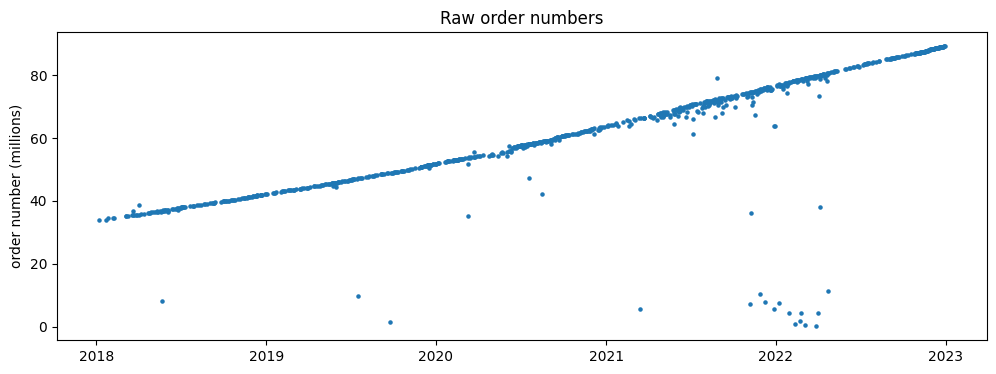

In [771]:
# Raw order numbers over time
plt.figure(figsize=(12, 4))
plt.scatter(orders["date"], orders["order_number"] / 1e6, s=5)
plt.title("Raw order numbers")
plt.ylabel("order number (millions)")
plt.show()

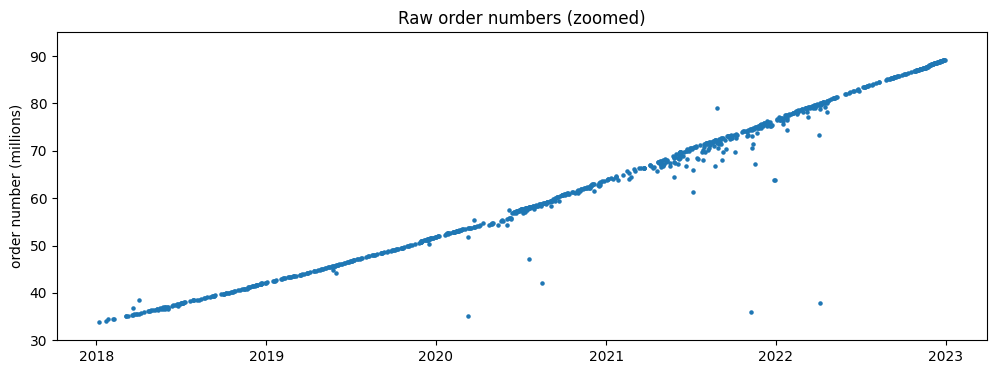

In [772]:
# Raw order numbers: zoomed in (excludes extreme values)
plt.figure(figsize=(12, 4))
plt.scatter(orders["date"], orders["order_number"] / 1e6, s=5)
plt.ylim(30, 95)
plt.title("Raw order numbers (zoomed)")
plt.ylabel("order number (millions)")
plt.show()

Rows: 143 | Decreases: 62


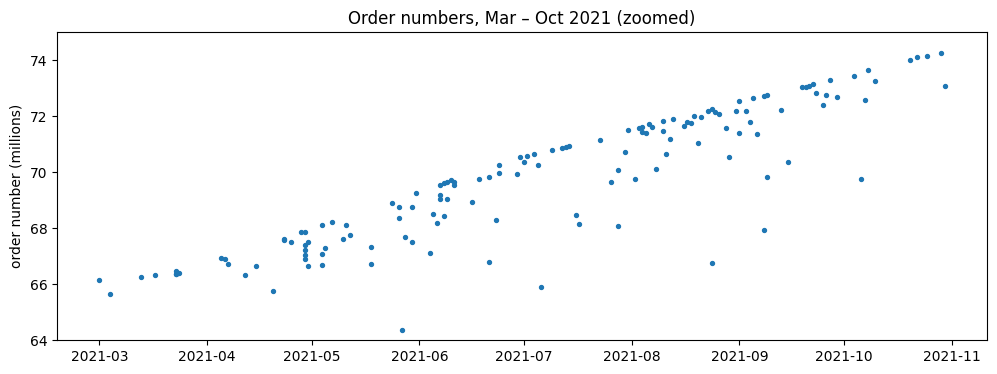

In [773]:
# Zoom into the noisiest stretch: Mar – Oct 2021
w = orders[(orders["date"] >= "2021-03-01") & (orders["date"] <= "2021-10-31")]
print("Rows:", len(w), "| Decreases:", (w["order_number"].diff() < 0).sum())

plt.figure(figsize=(12, 4))
plt.scatter(w["date"], w["order_number"] / 1e6, s=8)
plt.ylim(64, 75)
plt.title("Order numbers, Mar – Oct 2021 (zoomed)")
plt.ylabel("order number (millions)")
plt.show()

### Conclusion from the order-number plots

1. **A clear true series exists:** order numbers rise smoothly from ~34M (2018) to ~89M (end 2022), steepening from 2020 as order volumes grew.
2. **Three types of bad values**, from easy to hard to remove:
   - **Near-zero values** (17 points): impossible values, easy to remove.
   - **Isolated far-off points**, above or below the line: easy to detect against their neighbours.
   - **Stale values slightly below the line**: close to the trend and very common, the main cleaning challenge.
3. **Errors are one-sided:** almost all bad values are **too low**, so the true series is the **upper edge** of the data.
4. **Noise is concentrated in mid-2020 to mid-2022:** in Mar – Oct 2021, 62 of 143 rows (43%) are decreases. The data is clean before 2020 and from mid-2022.



## Transaction Data Analysis

In [774]:
# Is every day present, with no duplicates?
expected = (txn["date"].max() - txn["date"].min()).days + 1
print("Rows:", len(txn), "| Expected days:", expected, "| Duplicate dates:", txn["date"].duplicated().sum())

Rows: 1826 | Expected days: 1826 | Duplicate dates: 0


In [775]:
# Any zeros or negative values?
cols = ["total_spend_index", "gross_orders_index", "weekly_active_users_index"]
print((txn[cols] <= 0).sum())
txn[(txn[cols] <= 0).any(axis=1)]

total_spend_index            1
gross_orders_index           1
weekly_active_users_index    0
dtype: int64


,date,total_spend_index,gross_orders_index,weekly_active_users_index
40,2018-02-10,0.0,0.0,2.210275


In [776]:
# Yearly averages of each column
txn.groupby(txn["date"].dt.year)[cols].mean().round(2)

,total_spend_index,gross_orders_index,weekly_active_users_index
date,,,
2018,7.34,7.64,10.05
2019,27.61,28.40,38.32
2020,98.46,111.82,113.50
2021,197.80,213.48,184.36
2022,240.92,235.81,223.35


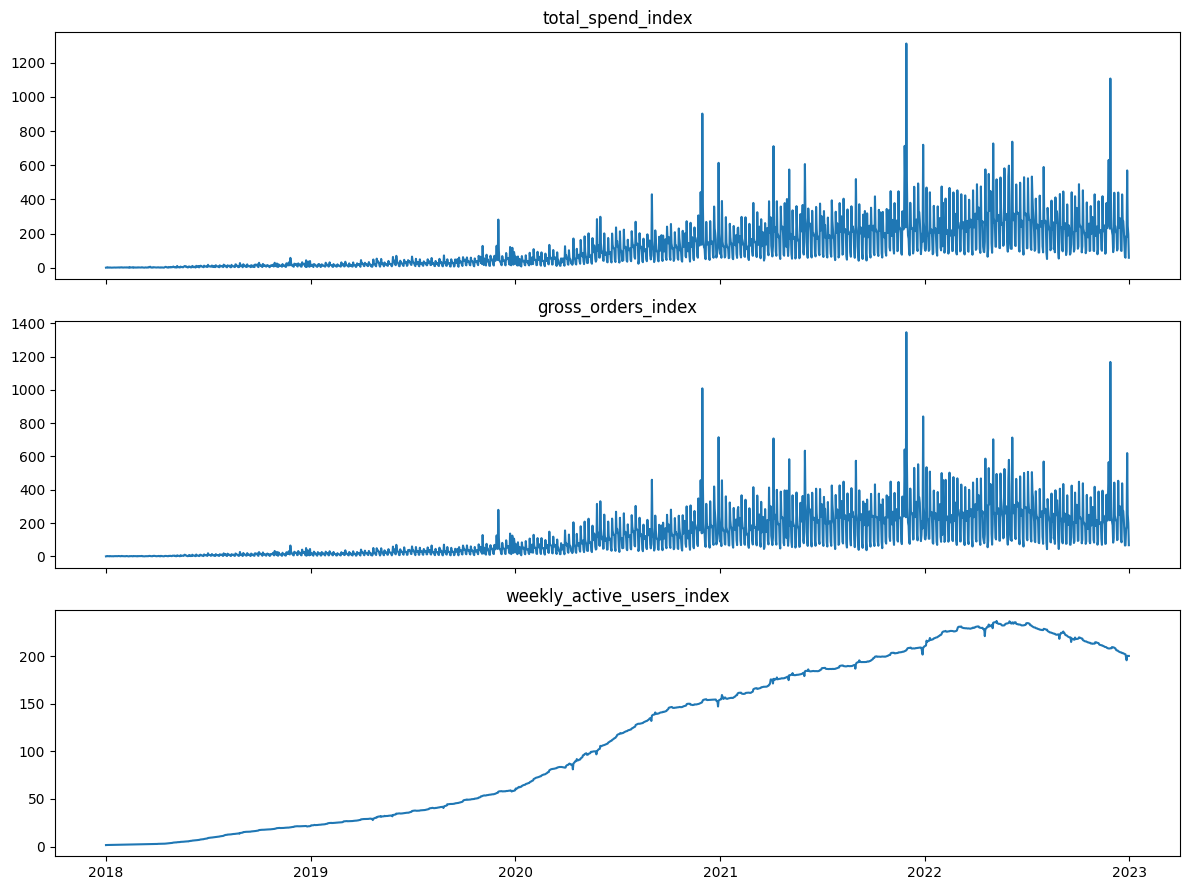

In [777]:
# Each column over time
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, col in zip(axes, cols):
    ax.plot(txn["date"], txn[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [778]:
# Panel growth vs revenue growth, 2018 → 2022
wau = txn.groupby(txn["date"].dt.year)["weekly_active_users_index"].mean()
spend = txn.groupby(txn["date"].dt.year)["total_spend_index"].mean()
print("Panel (WAU) grew:", round(wau.iloc[-1] / wau.iloc[0], 1), "x")
print("Raw spend grew:", round(spend.iloc[-1] / spend.iloc[0], 1), "x")
print("Revenue per day grew:", round(yearly["rev_per_day"].iloc[-1] / yearly["rev_per_day"].iloc[0], 1), "x")

Panel (WAU) grew: 22.2 x
Raw spend grew: 32.8 x
Revenue per day grew: 1.8 x


In [779]:
# When did the panel peak, and how much did it shrink by the end of 2022?
wau_daily = txn.set_index("date")["weekly_active_users_index"]
print("Peak WAU:", round(wau_daily.max(), 1), "on", wau_daily.idxmax().date())
print("WAU on 31 Dec 2022:", round(wau_daily.iloc[-1], 1))
print("Change from peak:", round((wau_daily.iloc[-1] / wau_daily.max() - 1) * 100, 1), "%")

Peak WAU: 237.1 on 2022-05-09
WAU on 31 Dec 2022: 200.4
Change from peak: -15.5 %


In [780]:
# Spend per active panel user, yearly average
yearly_txn = txn.groupby(txn["date"].dt.year)[cols].mean()
spend_per_user = yearly_txn["total_spend_index"] / yearly_txn["weekly_active_users_index"]
display(spend_per_user.round(2))
print("Spend per panel user grew:", round(spend_per_user.iloc[-1] / spend_per_user.iloc[0], 1), "x")

,0
date,
2018,0.73
2019,0.72
2020,0.87
2021,1.07
2022,1.08


Spend per panel user grew: 1.5 x


In [781]:
# Typical day-to-day % change in spend, by year (bigger = noisier)
daily_change = np.log(txn.set_index("date")["total_spend_index"].replace(0, np.nan)).diff().abs()
daily_change.groupby(daily_change.index.year).median().round(2)

,total_spend_index
date,
2018,0.53
2019,0.37
2020,0.38
2021,0.36
2022,0.32


In [782]:
# Top 5 days by spend (are the biggest spikes real events?)
txn.nlargest(5, "total_spend_index")[["date", "total_spend_index", "gross_orders_index"]]

,date,total_spend_index,gross_orders_index
1428,2021-11-29,1312.774732,1346.263911
1792,2022-11-28,1107.738568,1167.885533
1064,2020-11-30,902.300415,1009.220986
1617,2022-06-06,737.739491,713.672496
1583,2022-05-03,727.494455,703.020668


### Observation: transaction data

**Completeness**
- **No missing or duplicate days:** 1,826 rows for 1,826 calendar days (1 Jan 2018 – 31 Dec 2022).
- **One zero day:** 10 Feb 2018 has spend = 0 and orders = 0, while WAU is 2.21. Almost certainly a data dropout rather than a genuine zero, so it will be filled during cleaning.

**Patterns (from the plots)**
- **Strong day-of-week pattern:** spend and orders swing up and down within every week. This is normal shopping behaviour, not an error.
- **Spend and orders move together** almost exactly.
- **Genuine spikes:** the three largest spend days are **29 Nov 2021 (1,313), 28 Nov 2022 (1,108) and 30 Nov 2020 (902)**, all **Cyber Monday**. Two further large spikes occur on **3 May 2022 and 6 Jun 2022** (~730), possibly promotional events. Orders spike on the same days, so these are real activity and **must not be removed as outliers**.

**The panel-growth problem**

| 2018 → 2022 (yearly averages) | Growth |
|---|---|
| Panel size (WAU) | **22.2×** |
| Raw spend | **32.8×** |
| Spend per panel user (spend ÷ WAU) | **1.5×** |
| Reported revenue per day | **1.8×** |

- Raw spend grew 33× while revenue grew only 1.8×, so **raw spend mainly measures the panel getting bigger**, not ABC growing.
- Spend per panel user grew 1.5×, much closer to revenue's 1.8×, so **dividing by WAU gives a fairer measure** of ABC's activity.
- Spend per user was flat in 2018 – 2019 (0.73, 0.72), rose in 2020 – 2021 (0.87, 1.07) and levelled off in 2022 (1.08), matching the revenue story: growth during COVID, then a plateau.
- **The panel shrank during the test period:** WAU peaked at 237.1 on 9 May 2022 and fell to 200.4 by 31 Dec 2022 (−15.5%). Raw spend would therefore understate 2022 Q4, which is another reason to normalise by WAU.

**Noise**
- 2018 is noisier: the typical day-to-day change in spend (log scale) is **0.53 in 2018**, vs **0.32 – 0.38** in 2019 – 2022, because the panel was small and a few users could swing the numbers.
- Summing daily values over each reporting period will average out most of this noise.

**Consequence for cleaning and features**
1. Fill the one zero day (10 Feb 2018).
2. **Keep** the Cyber Monday and other genuine spikes.
3. **Normalise spend and orders by WAU** before using them as features.
4. Sum daily values over each period's **exact start and end dates**.
5. Treat 2018 features as less reliable (small panel).

## Data Issues Found

Severity: 🔴 High = must fix, or the model will be wrong · 🟠 Medium = must handle carefully · 🟢 Low = note as a limitation

### Order numbers

| # | Issue | Evidence | Severity | Plan |
|---|---|---|---|---|
| 1 | **Stale values slightly below the true line** | Fuzzy band mid-2020 – mid-2022; 62 of 143 rows are decreases in Mar – Oct 2021 | 🔴 High | Keep the upper edge: enforce "only increases" and treat low values more strictly than high ones (Stage 2) |
| 2 | **Impossible decreases** | 211 decreases, all across different dates | 🔴 High | Remove the values causing them (Stage 2) |
| 3 | **Near-zero values** | 17 values below 15M (mostly Nov 2021 – Apr 2022) | 🔴 High, but easy | Remove: far from neighbours (Stage 2) |
| 4 | **Isolated far-off values** | e.g. 35M on 10 Mar 2020; 79M on 27 Aug 2021 (neighbours ~72M) | 🔴 High, but easy | Remove: far from neighbours (Stage 2) |
| 5 | **Multiple values on the same date** | 102 dates have 2 – 5 conflicting values | 🟠 Medium | Resolve after removing bad values (keep one value per date) (Stage 2) |
| 6 | **Missing days** | Only 740 of 1,819 days observed; median gap 2 days, longest 25 days | 🟠 Medium | Interpolate the **cumulative** order number to every day, then difference (Stage 2) |
| 7 | **Gap across a period boundary** | 8 Feb – 5 Mar 2018 spans the end of 2018 Q1; ~480,000 orders split by estimate | 🟢 Low | Note as a limitation; re-check boundaries after cleaning |
| 8 | **Data starts after the first period begins** | First observation 7 Jan 2018; 2018 Q1 starts 1 Jan, so 1 – 6 Jan have no data | 🟢 Low | Extrapolate from 31 Dec 2017 to 7 Jan 2018 (7 days) at the early-2018 rate (Stage 4) |

### Transaction data

| # | Issue | Evidence | Severity | Plan |
|---|---|---|---|---|
| 9 | **Panel growth distorts raw spend** | WAU grew 22.2×, raw spend 32.8×, revenue only 1.8× | 🔴 High | Normalise spend and orders by WAU; spend per user grew 1.5× (Stage 3) |
| 10 | **Panel shrank during the test period** | WAU peaked at 237.1 (9 May 2022), fell to 200.4 by 31 Dec 2022 (−15.5%) | 🔴 High | Covered by normalising by WAU (Stage 3) |
| 11 | **Noisy early data** | Typical daily change 0.53 in 2018 vs 0.32 – 0.38 later | 🟠 Medium | Sum over periods to average out noise; treat 2018 as less reliable (Stages 4 – 5) |
| 12 | **One zero day** | 10 Feb 2018: spend = 0, orders = 0, WAU = 2.21 | 🟢 Low | Fill from neighbouring days (Stage 3) |
| 13 | **WAU covers the whole panel, not just ABC shoppers** | Stated in the brief | 🟢 Low | Note as a caveat: changes in panel composition could shift the ratio |

### Reported data

| # | Issue | Evidence | Severity | Plan |
|---|---|---|---|---|
| 14 | **Periods are not calendar quarters** | Q1 = Jan – Feb, Q2 = Mar – Jun, Q3 = Jul – Aug, Q4 = Sep – Dec; 59 – 122 days | 🟠 Medium | Build features over each period's exact dates (Stage 4) |
| 15 | **Period definitions changed in 2022** | June moved from Q2 to Q3 (both 92 days) | 🟠 Medium | Use exact dates; don't compare 2022 Q2 / Q3 with earlier years by label |
| 16 | **Leap year** | 2020 Q1 = 60 days | 🟢 Low | Handled automatically by using exact dates |

### Checked, and not a problem
- All date columns are real dates; no missing or duplicate days in the transaction data.
- Same-day order numbers are already in ascending order, so no decrease is a sorting artefact.
- Cyber Monday spikes (30 Nov 2020, 29 Nov 2021, 28 Nov 2022) and the May / June 2022 spikes are **genuine activity**: keep them.
- The 2022 Q4 test period falls in a clean stretch of order-number data, and its boundaries are observed within 1 – 2 days.

### Modelling challenges (not data errors, but they shape the approach)
- **2022 Q4 revenue fell 7.3% year-over-year**, and 2022 broke the usual Q4 peak. A trend-based model would over-predict, so the model must rely on spend and order data from within the period.
- **Only 19 training periods**, so models must stay simple (1 – 2 features).

# Stage 2: Order Data Cleaning

In [783]:
# Working copy of the order numbers, sorted by date (and by value within a date)
on = orders.sort_values(["date", "order_number"]).reset_index(drop=True).copy()

# Track why each row is removed: an empty string means "kept"
on["reason"] = ""

print("Rows:", len(on))
on.head()

Rows: 856


,date,order_number,reason
0,2018-01-07,33841906,
1,2018-01-22,34008921,
2,2018-01-25,34397468,
3,2018-02-06,34434432,
4,2018-02-08,34579365,


**Step 2.0:** created a working copy `on` (856 rows) sorted by date, with a `reason` column. Rows are labelled rather than deleted, so every removal can be traced.

In [784]:
# Naive approach: keep a value only if it is higher than the last kept value
keep = []
last_kept = -1                      # start below any possible order number
for value in on["order_number"]:
    if value > last_kept:
        keep.append(True)
        last_kept = value           # this becomes the new bar to beat
    else:
        keep.append(False)

naive = on[keep]
print("Kept:", len(naive), "| Dropped:", len(on) - len(naive))

Kept: 470 | Dropped: 386


In [785]:
# Find which kept values caused the most drops after them
check = on.copy()
check["kept"] = keep                           # True/False from the naive rule
check["run_id"] = check["kept"].cumsum()       # every kept value starts a new group

blockers = check.groupby("run_id").agg(
    blocker_date=("date", "first"),            # the kept value that starts the group
    blocker_value=("order_number", "first"),
    rows_dropped_after=("kept", lambda s: (~s).sum()))   # dropped rows that follow it

blockers.sort_values("rows_dropped_after", ascending=False).head(5)

,blocker_date,blocker_value,rows_dropped_after
run_id,,,
336,2021-08-27,79082549,129
12,2018-04-02,38593423,48
213,2020-06-06,57479504,17
210,2020-03-24,55410669,15
306,2021-04-28,67875459,9


In [786]:
# Rows around the too-high value on 27 Aug 2021
on[(on["date"] >= "2021-08-25") & (on["date"] <= "2021-08-31")]

,date,order_number,reason
564,2021-08-25,72162614,
565,2021-08-26,72087158,
566,2021-08-27,79082549,
567,2021-08-28,71572545,
568,2021-08-29,70545126,
569,2021-08-31,72196072,


In [787]:
# After that value, when does the naive rule keep anything again?
first_after = naive[naive["date"] > "2021-08-27"].iloc[0]
print("Next value kept after 27 Aug 2021:", first_after["date"].date(), f"{first_after['order_number']:,}")

dropped_in_between = on[(on["date"] > "2021-08-27") & (on["date"] < first_after["date"])]
print("Values dropped in between:", len(dropped_in_between))

Next value kept after 27 Aug 2021: 2022-03-10 79,110,981
Values dropped in between: 129


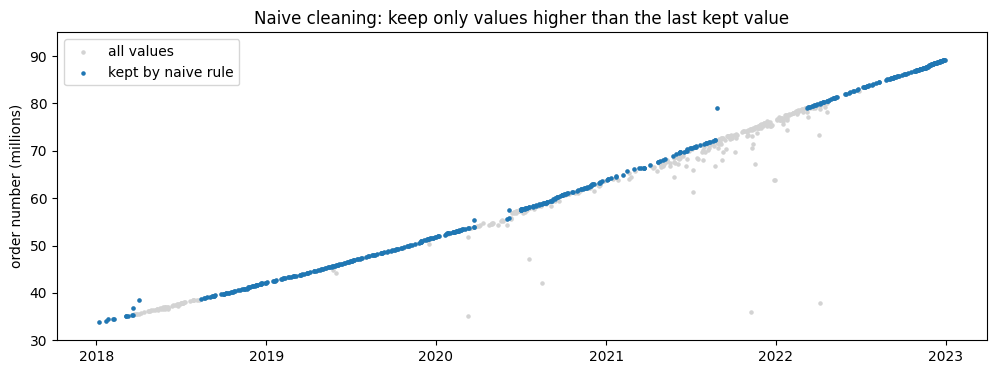

In [788]:
# Plot: values kept by the naive rule vs all values
plt.figure(figsize=(12, 4))
plt.scatter(on["date"], on["order_number"] / 1e6, s=5, color="lightgrey", label="all values")
plt.scatter(naive["date"], naive["order_number"] / 1e6, s=5, label="kept by naive rule")
plt.ylim(30, 95)
plt.title("Naive cleaning: keep only values higher than the last kept value")
plt.ylabel("order number (millions)")
plt.legend()
plt.show()

**Step 2.1 – naive rule (rejected):** keeping only values higher than the last kept value retains 470 rows and drops 386. It fails because a single too-high value (79M on 27 Aug 2021, neighbours ~72M) raises the bar, so the next 129 correct values are dropped until 10 Mar 2022.

The largest blocker, 79M on 27 Aug 2021, caused 129 drops; a second, 38.6M on 2 Apr 2018, caused 48

**Note:** obvious errors must be removed first, and each value should be judged against its neighbours on both sides, not only the previous value.

In [789]:
# Median of the 21 values around each row (10 before, itself, 10 after)
neighbour_median = on["order_number"].rolling(21, center=True, min_periods=5).median()

# How far each value is from its neighbours' median, as a fraction (0.10 = 10%)
rel_dev = (on["order_number"] / neighbour_median - 1).abs()

# Label values more than 10% away
gross = rel_dev > 0.10
on.loc[gross, "reason"] = "gross error"

print("Gross errors flagged:", gross.sum())
print("Below their neighbours:", (on["order_number"] < neighbour_median)[gross].sum(),
      "| Above:", (on["order_number"] > neighbour_median)[gross].sum())

Gross errors flagged: 25
Below their neighbours: 25 | Above: 0


In [790]:
# Look at the values flagged as gross errors
on[gross].assign(neighbour_median=neighbour_median[gross].round(0),
                 pct_off=(rel_dev[gross] * 100).round(1))

,date,order_number,reason,neighbour_median,pct_off
30,2018-05-23,8084373,gross error,36638240.0,77.9
182,2019-07-17,9778659,gross error,47048832.0,79.2
202,2019-09-24,1323105,gross error,48785380.0,97.3
279,2020-03-10,35144955,gross error,53434779.0,34.2
346,2020-07-20,47204230,gross error,57944281.0,18.5
371,2020-08-17,42168587,gross error,58816936.0,28.3
461,2021-03-15,5615155,gross error,66266843.0,91.5
528,2021-07-06,61308679,gross error,70267566.0,12.7
606,2021-11-07,7261603,gross error,74106081.0,90.2
607,2021-11-08,36054177,gross error,74144398.0,51.4


In [791]:
# How much is left to fix?
kept = on[on["reason"] == ""]
print("Rows kept:", len(kept), "| Decreases remaining:", (kept["order_number"].diff() < 0).sum())

Rows kept: 831 | Decreases remaining: 194


In [792]:
# Check the two biggest blockers found in Step 2.1
for d in ["2021-08-27", "2018-04-02"]:
    rows = on["date"] == d
    display(on[rows].assign(neighbour_median=neighbour_median[rows].round(0),
                            pct_off=(rel_dev[rows] * 100).round(1)))

,date,order_number,reason,neighbour_median,pct_off
566,2021-08-27,79082549,,71965840.0,9.9


,date,order_number,reason,neighbour_median,pct_off
14,2018-04-02,38593423,,35750924.0,8.0


In [793]:
# Effect of different thresholds on rows kept and decreases remaining
for t in [0.10, 0.05, 0.03]:
    k = on[rel_dev <= t]
    print(f"Threshold {t:.0%}: rows kept {len(k)} | decreases remaining {(k['order_number'].diff() < 0).sum()}")

Threshold 10%: rows kept 831 | decreases remaining 194
Threshold 5%: rows kept 823 | decreases remaining 190
Threshold 3%: rows kept 808 | decreases remaining 179


**Step 2.2 – gross errors**

**Method:** for each value, take the median of its 21 neighbouring values (10 before, itself, 10 after) and flag it if it is more than **10%** away. The median is used because it isn't pulled off by a few extreme values. Flagged rows are **labelled** `"gross error"` in the `reason` column, not deleted; later steps only use rows with an empty `reason`.

**Result**
- **25 values flagged, all below their neighbours** (none above).
  - **17 near-zero values** (0.08M – 11.3M), 78 – 100% below their neighbours, e.g. 754,349 on 11 Feb 2022 vs a neighbour median of 77.8M. Likely truncated numbers or dropped digits.
  - **8 large drops**, 12.7 – 52.4% below their neighbours, e.g. 35.1M on 10 Mar 2020 (median 53.4M) and 36.1M on 8 Nov 2021 (median 74.1M).
- **Rows kept: 831.** Decreases fell from 211 to **194**.

**What it missed**
- The two blockers from Step 2.1 are just under the threshold: **79M on 27 Aug 2021 (9.9% above)** and **38.6M on 2 Apr 2018 (8.0% above)**.
- The many **stale values** slightly below the true line, often only 0.5 – 3% off.

**Why not use a lower threshold?**

| Threshold | Rows kept | Decreases remaining |
|---|---|---|
| 10% | 831 | 194 |
| 5% | 823 | 190 |
| 3% | 808 | 179 |

- Lowering the threshold barely helps: even 3% leaves 179 decreases.
- At 5%, the 8 extra flags are all genuine errors (the 2 blockers + 6 stale values), so 5% would also be defensible.
- But the remaining stale values are too close to the line for this rule. Catching them would need ~1 – 2%, which risks flagging **correct** values: the 21-value window spans ~2 months in sparse 2018 (vs ~3 weeks in 2022), so correct values can sit a few % from the median simply because orders grew within the window. In noisy 2021, stale values are also common enough to **pull the median itself down**.

**Decision:** keep 10% so this step removes only **obvious** errors. The stale values are handled by the asymmetric trend filter (Step 2.3), and the remaining too-high values by enforcing "only goes up" (Step 2.4).



In [794]:
# Step 2.3 Part A: fit a smooth trend line (LOWESS) through the rows not yet flagged
ok = (on["reason"] == "").to_numpy()                                    # rows still kept after Step 2.2
t  = (on["date"] - on["date"].min()).dt.days.to_numpy(dtype=float)       # time as "days since first date"
y  = on["order_number"].to_numpy(dtype=float)

FRAC = 0.05      # each local fit uses the nearest 5% of points (~40 points, roughly 1–3 months)

fitted = lowess(y[ok], t[ok], frac=FRAC, it=1, return_sorted=False, delta=0)
trend = np.interp(t, t[ok], fitted)                                      # trend value for every row

print("Trend computed for", len(trend), "rows")

Trend computed for 856 rows


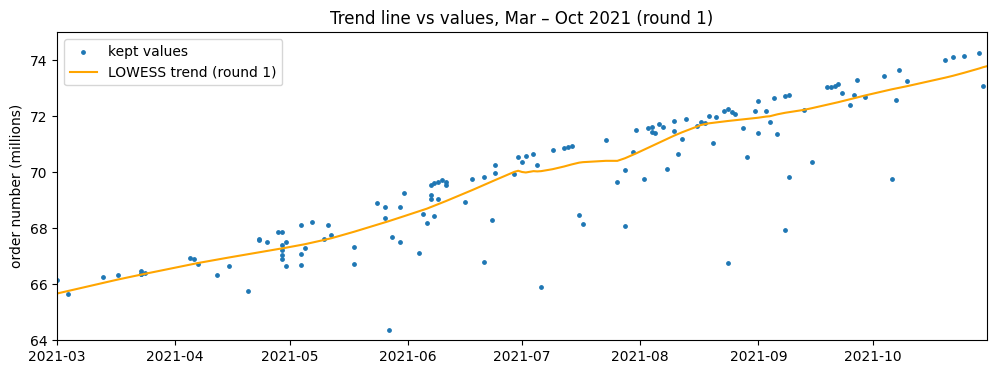

In [795]:
# Plot the kept values and the trend line, zoomed into the noisy period
plt.figure(figsize=(12, 4))
plt.scatter(on["date"][ok], y[ok] / 1e6, s=6, label="kept values")
plt.plot(on["date"], trend / 1e6, color="orange", linewidth=1.5, label="LOWESS trend (round 1)")
plt.xlim(pd.Timestamp("2021-03-01"), pd.Timestamp("2021-10-31"))
plt.ylim(64, 75)
plt.title("Trend line vs values, Mar – Oct 2021 (round 1)")
plt.ylabel("order number (millions)")
plt.legend()
plt.show()

In [796]:
# Step 2.3 Part B: one round of asymmetric filtering
resid = y - trend                                             # distance from the trend (negative = below)

# Typical distance from the trend, measured robustly (like a standard deviation, but not fooled by outliers)
scale = 1.4826 * np.median(np.abs(resid[ok]))
scale = max(scale, 10_000)                                    # floor: never treat < 10,000 orders as unusual

BELOW, ABOVE = 3.5, 4.0                                       # stricter below the trend than above it
too_low  = ok & (resid < -BELOW * scale)
too_high = ok & (resid >  ABOVE * scale)

print(f"Typical distance from trend: {scale:,.0f} orders")
print("Flagged too low:", too_low.sum(), "| too high:", too_high.sum())

Typical distance from trend: 95,348 orders
Flagged too low: 92 | too high: 80


In [797]:
# Step 2.3 Part C: repeat the asymmetric filter until no more values are removed
FRAC, BELOW, ABOVE = 0.05, 3.5, 4.0

keep = (on["reason"] == "").to_numpy()        # start from the rows kept after Step 2.2
t = (on["date"] - on["date"].min()).dt.days.to_numpy(dtype=float)
y = on["order_number"].to_numpy(dtype=float)

for round_no in range(1, 31):                 # safety limit of 30 rounds
    # 1. redraw the trend using only the values still kept
    fitted = lowess(y[keep], t[keep], frac=FRAC, it=1, return_sorted=False, delta=0)
    trend = np.interp(t, t[keep], fitted)

    # 2. measure distances from the trend
    resid = y - trend
    scale = max(1.4826 * np.median(np.abs(resid[keep])), 10_000)

    # 3. keep only values within the allowed band (stricter below than above)
    new_keep = keep & (resid > -BELOW * scale) & (resid < ABOVE * scale)

    removed = (keep & ~new_keep).sum()
    print(f"Round {round_no:2d}: scale {scale:9,.0f} | removed {removed:3d} | kept {new_keep.sum()}")

    if removed == 0:                          # nothing changed, so stop
        break
    keep = new_keep

# 4. label everything this step removed
far = (on["reason"] == "").to_numpy() & ~keep
on.loc[far, "reason"] = "far from trend"
print("\nLabelled 'far from trend':", far.sum())

Round  1: scale    95,348 | removed 172 | kept 659
Round  2: scale    49,684 | removed  69 | kept 590
Round  3: scale    39,223 | removed  36 | kept 554
Round  4: scale    33,695 | removed  10 | kept 544
Round  5: scale    32,977 | removed   5 | kept 539
Round  6: scale    30,823 | removed   5 | kept 534
Round  7: scale    29,448 | removed   9 | kept 525
Round  8: scale    28,438 | removed   8 | kept 517
Round  9: scale    27,248 | removed   8 | kept 509
Round 10: scale    26,346 | removed   5 | kept 504
Round 11: scale    25,634 | removed   5 | kept 499
Round 12: scale    25,929 | removed   1 | kept 498
Round 13: scale    25,852 | removed   0 | kept 498

Labelled 'far from trend': 333


In [798]:
# Rows kept and decreases remaining after Step 2.3
kept = on[on["reason"] == ""]
print("Rows kept:", len(kept), "| Decreases remaining:", (kept["order_number"].diff() < 0).sum())
on["reason"].replace("", "kept").value_counts()

Rows kept: 498 | Decreases remaining: 25


,count
reason,
kept,498
far from trend,333
gross error,25


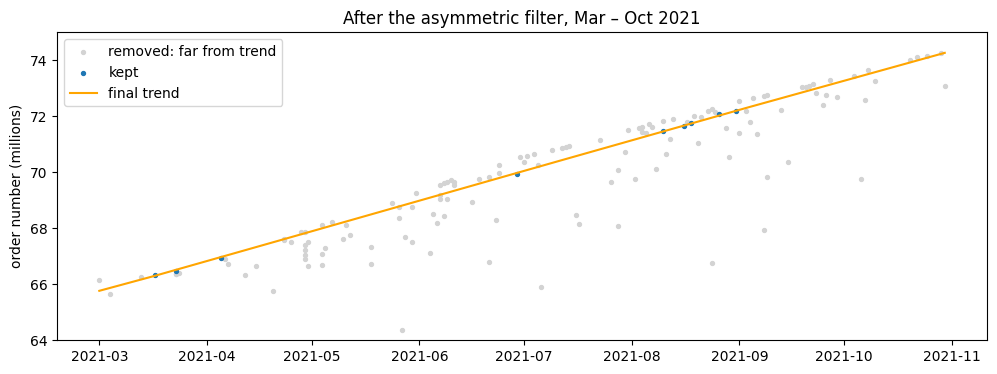

In [799]:
# Plot: kept vs removed values and the final trend, Mar – Oct 2021
w = (on["date"] >= "2021-03-01") & (on["date"] <= "2021-10-31")
k = w & (on["reason"] == "")
r = w & (on["reason"] == "far from trend")

plt.figure(figsize=(12, 4))
plt.scatter(on["date"][r], on["order_number"][r] / 1e6, s=8, color="lightgrey", label="removed: far from trend")
plt.scatter(on["date"][k], on["order_number"][k] / 1e6, s=8, label="kept")
plt.plot(on["date"][w], trend[w.to_numpy()] / 1e6, color="orange", linewidth=1.5, label="final trend")
plt.ylim(64, 75)
plt.title("After the asymmetric filter, Mar – Oct 2021")
plt.ylabel("order number (millions)")
plt.legend()
plt.show()

**Step 2.3 – stale values (asymmetric trend filter)**

**Method**
1. **Part A:** fit a smooth trend line (LOWESS, `frac = 0.05`, i.e. each local fit uses the nearest ~5% of points) through the values kept after Step 2.2.
2. **Part B:** measure each value's distance from the trend (residual), and the typical distance (`scale` = 1.4826 × median absolute residual, floor 10,000 orders). Flag values more than **3.5 × scale below** or **4 × scale above** the trend. The filter is **stricter below** because the errors are mostly low.
3. **Part C:** repeat: remove flagged values, refit the trend on what's left, re-measure, until a round removes nothing. Removed rows are labelled `"far from trend"`.

**Result**
- Round 1 (Part B, single pass): scale **95,348**; **92** values flagged too low and **80** too high.
- The loop **converged after 13 rounds**. The scale fell from **95,348 to 25,852** orders, and **333** values were labelled `"far from trend"`.
- **Rows kept: 498.** Decreases fell from 194 to **25**.

**Answers**
1. **Why does the scale shrink?** Each round removes the values furthest from the trend, so the remaining values are tighter around it and the typical distance falls. The filter therefore gets stricter as the data gets cleaner. Most of the change happens in the first 3 rounds (172, 69, 36 removed), then it settles.
2. **How did the trend line move?** In round 1 (Part A plot) it ran through the middle of the noisy 2021 band, pulled down by stale values. After convergence it runs along the **top edge**, the true series.
3. **What are the 25 remaining decreases?** Mostly values slightly above the true line that survived the lenient "above" limit, and stale values close enough to the line to pass. Step 2.4 ("only goes up") removes these.


**Note:** in the noisiest stretch (2020 – 2021), the filter removes many values, including some that look correct. This mainly reduces detail within periods: the straight-line fill in Step 2.6 runs through the remaining values, so period totals are less affected. Even so, **order counts for 2020 – 2021 are the least certain** in the data. The 2022 Q4 test period is in a clean stretch and unaffected.

In [800]:
# Step 2.4: longest increasing subsequence (LIS)
def longest_increasing_subsequence(values):
    """Return a True/False mask marking the longest strictly increasing subsequence."""
    tails_val, tails_idx = [], []            # smallest possible "last value" for increasing runs of each length
    prev = np.full(len(values), -1)          # for each value, the index of the value before it in its run
    for i, v in enumerate(values):
        k = bisect_left(tails_val, v)        # longest run this value can extend
        if k == len(tails_val):
            tails_val.append(v); tails_idx.append(i)
        else:
            tails_val[k], tails_idx[k] = v, i
        prev[i] = tails_idx[k - 1] if k > 0 else -1
    # walk backwards from the end of the longest run to mark its members
    mask = np.zeros(len(values), dtype=bool)
    i = tails_idx[-1]
    while i != -1:
        mask[i] = True
        i = prev[i]
    return mask

In [801]:
# Step 2.4: apply LIS to the rows kept after Step 2.3
ok = on["reason"] == ""                                            # rows kept after Step 2.3
in_lis = longest_increasing_subsequence(on.loc[ok, "order_number"].to_numpy())

breaks = on.index[ok][~in_lis]                                     # kept rows NOT in the longest increasing run
on.loc[breaks, "reason"] = "breaks monotonicity"

kept = on[on["reason"] == ""]
print("Removed (breaks monotonicity):", len(breaks))
print("Rows kept:", len(kept), "| Decreases remaining:", (kept["order_number"].diff() < 0).sum())
print("Dates with more than one value:", kept["date"].duplicated().sum())
on["reason"].replace("", "kept").value_counts()

Removed (breaks monotonicity): 26
Rows kept: 472 | Decreases remaining: 0
Dates with more than one value: 27


,count
reason,
kept,472
far from trend,333
breaks monotonicity,26
gross error,25


In [802]:
# Which values did LIS remove?
on.loc[breaks, ["date", "order_number"]]

,date,order_number
33,2018-05-25,36935997
49,2018-07-02,37877575
107,2018-12-20,41898367
125,2019-02-20,43328739
204,2019-09-29,49006640
224,2019-11-29,50818986
228,2019-12-01,50893694
230,2019-12-07,51129817
233,2019-12-13,51290742
243,2019-12-21,51515222


In [803]:
# Would the naive rule (Step 2.1) do worse on these already-cleaned rows?
v = on.loc[ok, "order_number"].to_numpy()
naive_keep = v > np.maximum.accumulate(np.r_[-1, v[:-1]])
print("Naive rule would remove:", (~naive_keep).sum(), "| LIS removes:", (~in_lis).sum())

Naive rule would remove: 27 | LIS removes: 26


In [804]:
# How big are the conflicts LIS removed? Compare each removed value with the next kept value
kept_rows = on[on["reason"] == ""]
sizes = []
for idx, row in on.loc[breaks].iterrows():
    nxt = kept_rows[kept_rows.index > idx].iloc[0]
    sizes.append({"date": row["date"].date(),
                  "removed_value": row["order_number"],
                  "above_next_kept": row["order_number"] - nxt["order_number"],
                  "days_to_next_kept": (nxt["date"] - row["date"]).days})
sizes = pd.DataFrame(sizes)
print(sizes["above_next_kept"].describe().round(0))
sizes

count        26.0
mean       8719.0
std       40908.0
min     -160698.0
25%        4138.0
50%       14410.0
75%       24266.0
max       73862.0
Name: above_next_kept, dtype: float64


,date,removed_value,above_next_kept,days_to_next_kept
0,2018-05-25,36935997,10108,4
1,2018-07-02,37877575,19820,1
2,2018-12-20,41898367,8169,1
3,2019-02-20,43328739,14024,2
4,2019-09-29,49006640,14796,2
5,2019-11-29,50818986,30363,1
6,2019-12-01,50893694,24543,2
7,2019-12-07,51129817,3627,2
8,2019-12-13,51290742,23435,2
9,2019-12-21,51515222,2657,1


**Step 2.4 – enforce "only goes up" (longest increasing subsequence)**

**Method:** among the values kept after Step 2.3, keep the **largest possible set that strictly increases** in date order (the longest increasing subsequence, LIS), so the fewest values are removed. Values outside it are labelled `"breaks monotonicity"`.

**Result**
- **26 values removed.** **Rows kept: 472. Decreases remaining: 0.**
- **27 dates still have more than one value**, to be resolved in Step 2.5.
- Running total: kept 472 · far from trend 333 · breaks monotonicity 26 · gross error 25 (= 856).

**Answers**
1. **Why are decreases guaranteed to be 0?** By definition, the LIS only contains values that increase from one to the next, so any value that would create a decrease is outside it and removed.
2. **Why does the naive rule now do almost as well (27 vs 26), when in Step 2.1 it removed 386?** The blockers that broke it, **79M on 27 Aug 2021** and **38.6M on 2 Apr 2018**, were already removed in Step 2.3 (`"far from trend"`). With no blockers left, "keep only values above the highest so far" works almost as well. LIS is still used because it **guarantees** the fewest removals, whatever is left in the data.
3. **Can LIS tell which of two conflicting values is wrong?** No. When two neighbouring values conflict, it just removes whichever leaves the longest increasing run. But these conflicts are tiny: removed values sit a median of **~14,000 orders** (max ~74,000) above the next kept value, usually **1 – 2 days** later. That's under a day's orders (~25,000 – 40,000 per day), versus **~7 million** for the 79M blocker. They are most likely values recorded at different times of day, so either choice has a negligible effect on period totals.

**Note:** layering matters. LIS is only reliable here because Steps 2.2 – 2.3 removed the big errors first; on the raw data, any "only goes up" rule is easily distorted by a few large errors.

In [805]:
# Step 2.5: dates that still have more than one value after cleaning
kept = on[on["reason"] == ""]
per_date = kept.groupby("date")["order_number"]

multi = per_date.size()[per_date.size() > 1]
print("Dates with more than one value:", len(multi), "| rows on those dates:", multi.sum())
print("Values per date:", multi.value_counts().to_dict())

spread = (per_date.max() - per_date.min())[multi.index]      # gap between highest and lowest value that day
print(spread.describe().round(0))

Dates with more than one value: 25 | rows on those dates: 52
Values per date: {2: 23, 3: 2}
count        25.0
mean      37515.0
std       30773.0
min         160.0
25%       13688.0
50%       31718.0
75%       50129.0
max      118392.0
Name: order_number, dtype: float64


In [806]:
# One value per date: keep the highest (= latest reading of the day, closest to end-of-day)
clean = per_date.max()

print("Clean series:", len(clean), "dates")
print("Strictly increasing:", clean.is_monotonic_increasing and (clean.diff().dropna() > 0).all())
clean.head()

Clean series: 445 dates
Strictly increasing: True


,order_number
date,
2018-01-07,33841906
2018-02-06,34434432
2018-02-08,34579365
2018-03-05,35059326
2018-03-06,35147248


In [807]:
# How different would the series be if we used the median instead of the max?
diff = clean - per_date.median()
print(diff.describe().round(0))

count      445.0
mean      1014.0
std       5448.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max      59196.0
Name: order_number, dtype: float64


**Step 2.5 – one value per date**

**Method:** after Step 2.4, every remaining value belongs to a strictly increasing sequence, so when a date still has several values, **all of them passed every check**. They are most likely readings taken at different times of the same day. Since period totals need the **end-of-day** order number, the **highest (latest) value** on each date is kept (`max`).

**Result**
- **25 dates** had more than one value (**52 rows**: 23 dates with 2 values, 2 with 3). This matches Step 2.4's "27", which counted only the extra rows (23 × 1 + 2 × 2 = 27).
- **Clean series: 445 dates, strictly increasing.**

**Answers**
1. **Why are both values now likely correct, when in Stage 1 they "conflicted"?** In Stage 1, many same-day values were errors (stale or near-zero). After Steps 2.2 – 2.4, only values consistent with an increasing series remain, so same-day values now differ only because they were recorded at different times.
2. **Same-day spread vs a day's orders:** the median spread is **~31,700 orders** (max ~118,400), close to a typical day's orders (~25,000 – 40,000). This suggests readings taken at different points in the day, e.g. morning and evening.
3. **Does max vs median matter?** Barely. The two choices are identical on most dates, with a mean difference of **~1,000 orders** (max ~59,000), tiny compared with period totals of 1 – 5 million.


**Final Stage 2 audit so far:** 856 raw rows → 25 gross errors, 333 far from trend, 26 break monotonicity → 472 rows → **445 clean dates**.

In [808]:
# Compare the first raw values with the clean series: is each one still there?
early = orders.sort_values(["date", "order_number"]).head(6).copy()
early["in_clean_series"] = [(d in clean.index) and (clean.loc[d] == v)
                            for d, v in zip(early["date"], early["order_number"])]
early

,date,order_number,in_clean_series
0,2018-01-07,33841906,True
1,2018-01-22,34008921,False
2,2018-01-25,34397468,False
3,2018-02-06,34434432,True
4,2018-02-08,34579365,True
5,2018-03-05,35059326,True


In [809]:
# Which step removed them, and what orders per day would each value imply?
first = on.head(5).copy()
first["days_since_prev"] = first["date"].diff().dt.days
first["orders_per_day_since_prev"] = (first["order_number"].diff() / first["days_since_prev"]).round(0)
first["distance_from_trend"] = (y[:5] - trend[:5]).round(0)      # trend from the final round of Step 2.3

print("Normal rate between the KEPT values (7 Jan → 6 Feb):",
      round((clean.loc["2018-02-06"] - clean.loc["2018-01-07"]) / 30), "orders/day")
print("Step 2.3 limit below the trend: 3.5 ×", f"{scale:,.0f}", "=", f"{3.5 * scale:,.0f}", "orders")
first

Normal rate between the KEPT values (7 Jan → 6 Feb): 19751 orders/day
Step 2.3 limit below the trend: 3.5 × 25,852 = 90,483 orders


,date,order_number,reason,days_since_prev,orders_per_day_since_prev,distance_from_trend
0,2018-01-07,33841906,,NaN,NaN,884.0
1,2018-01-22,34008921,far from trend,15.0,11134.0,-158568.0
2,2018-01-25,34397468,far from trend,3.0,129516.0,164685.0
3,2018-02-06,34434432,,12.0,3080.0,-59525.0
4,2018-02-08,34579365,,2.0,72466.0,41888.0


**Observation – January 2018 values**

**What was removed:** comparing the first raw values with the clean series shows that **22 Jan 2018 (34,008,921)**, the brief's example, and **25 Jan 2018 (34,397,468)** did not survive cleaning. 7 Jan, 6 Feb and later values did.

**Why:** both were labelled `"far from trend"` in Step 2.3.
- **25 Jan** would imply **~129,500 orders/day** over 3 days, about 6× the normal rate (~19,750/day between the kept values on 7 Jan and 6 Feb). Clearly too high.
- **22 Jan** sits **158,568 below the trend**, beyond the limit of 3.5 × 25,852 ≈ 90,500, and implies only **~11,100 orders/day** since 7 Jan, about half the normal rate. Likely a stale value, though **borderline**.
- (The rates shown for 6 Feb and 8 Feb are distorted because they are calculated from the removed values.)

**Effect:** none on period totals. 7 Jan and 6 Feb are both kept, so the straight-line fill between them skips over 22 Jan, and 2018 Q1's total depends only on the values at its start and end.

In [810]:
# Step 2.6: put the clean series on a daily calendar and fill the gaps with straight lines
all_days = pd.date_range(clean.index.min(), clean.index.max(), freq="D")

cum_orders = clean.astype(float).reindex(all_days).interpolate(method="time")

print("Calendar days:", len(all_days), "| observed:", len(clean), "| filled in:", len(all_days) - len(clean))
print("Missing after filling:", cum_orders.isna().sum())
cum_orders.loc["2018-02-05":"2018-02-09"].round(0)

Calendar days: 1819 | observed: 445 | filled in: 1374
Missing after filling: 0


,order_number
2018-02-05,34414681.0
2018-02-06,34434432.0
2018-02-07,34506898.0
2018-02-08,34579365.0
2018-02-09,34598563.0


In [811]:
# Daily orders = today's order number minus yesterday's
daily_orders = cum_orders.diff()

print(daily_orders.describe().round(0))
print("Days with negative orders:", (daily_orders < 0).sum())
print("Average orders per day, by year:")
daily_orders.groupby(daily_orders.index.year).mean().round(0)

count      1818.0
mean      30435.0
std       12563.0
min         110.0
25%       23581.0
50%       30656.0
75%       36242.0
max      121742.0
Name: order_number, dtype: float64
Days with negative orders: 0
Average orders per day, by year:


,order_number
2018,23278.0
2019,26386.0
2020,32723.0
2021,35095.0
2022,34560.0


In [812]:
# The most extreme single days: real events at the top, timing noise at the bottom
print("Highest days:"); print(daily_orders.nlargest(3).round(0))
print("\nLowest days:"); print(daily_orders.nsmallest(3).round(0))
print("\nDays below 10,000 orders:", (daily_orders < 10_000).sum())

Highest days:
2022-11-26    121742.0
2020-11-27    119489.0
2020-07-28    115745.0
Name: order_number, dtype: float64

Lowest days:
2022-03-07    110.0
2019-03-31    496.0
2019-04-02    496.0
Name: order_number, dtype: float64

Days below 10,000 orders: 69


In [813]:
# Compare growth in cleaned orders per day with growth in revenue per day (from Stage 1)
orders_per_day = daily_orders.groupby(daily_orders.index.year).mean()
orders_per_day.index = orders_per_day.index.astype(str)          # match the 'year' labels in `yearly`

growth = pd.DataFrame({
    "orders_per_day": orders_per_day.round(0),
    "orders_yoy_%": (orders_per_day.pct_change() * 100).round(1),
    "rev_per_day": yearly["rev_per_day"].round(2),
    "revenue_yoy_%": yearly["yoy_%"],
})
growth

,orders_per_day,orders_yoy_%,rev_per_day,revenue_yoy_%
2018,23278.0,NaN,2.19,NaN
2019,26386.0,13.4,2.54,16.1
2020,32723.0,24.0,3.18,24.9
2021,35095.0,7.2,4.03,26.7
2022,34560.0,-1.5,4.02,-0.2


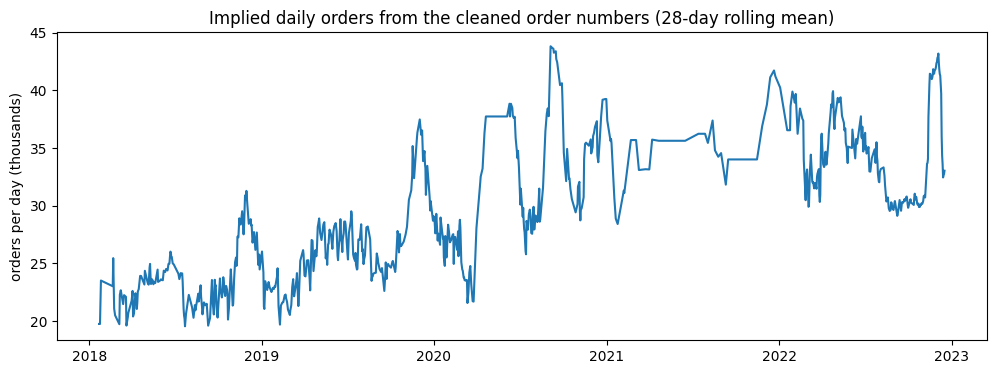

In [814]:
# Plot: implied daily orders (28-day rolling mean)
plt.figure(figsize=(12, 4))
plt.plot(daily_orders.index, daily_orders.rolling(28, center=True).mean() / 1e3)
plt.title("Implied daily orders from the cleaned order numbers (28-day rolling mean)")
plt.ylabel("orders per day (thousands)")
plt.show()

In [815]:
# How long are the gaps between clean values now?
clean_gaps = clean.index.to_series().diff().dt.days
print("Longest gap after cleaning:", clean_gaps.max(), "days, ending", clean_gaps.idxmax().date())
clean_gaps[clean_gaps >= 14].rename("gap_days").to_frame()

Longest gap after cleaning: 89.0 days, ending 2021-11-28


,gap_days
date,
2018-02-06,30.0
2018-03-05,25.0
2020-01-23,16.0
2020-06-17,73.0
2020-09-09,14.0
2020-12-16,15.0
2021-02-06,14.0
2021-03-17,39.0
2021-06-29,85.0


In [816]:
# For each period boundary: how far is the nearest clean value? (0 = the boundary day itself was observed)
clean_dates = clean.index.to_series().reset_index(drop=True)
rows = []
for _, p in reported.iterrows():
    b = p["start_date"] - pd.Timedelta(days=1)                  # last day of the previous period
    before, after = clean_dates[clean_dates <= b].max(), clean_dates[clean_dates > b].min()
    rows.append({"period_starting": p["period"], "boundary": b.date(),
                 "last_clean_before": before.date() if pd.notna(before) else None,
                 "next_clean_after": after.date() if pd.notna(after) else None,
                 "days_to_nearest": min((b - before).days if pd.notna(before) else 999,
                                        (after - b).days if pd.notna(after) else 999)})
boundary_after = pd.DataFrame(rows)
boundary_after

,period_starting,boundary,last_clean_before,next_clean_after,days_to_nearest
0,2018 Q1,2017-12-31,None,2018-01-07,7
1,2018 Q2,2018-02-28,2018-02-08,2018-03-05,5
2,2018 Q3,2018-06-30,2018-06-29,2018-07-03,1
3,2018 Q4,2018-08-31,2018-08-26,2018-09-03,3
4,2019 Q1,2018-12-31,2018-12-29,2019-01-01,1
5,2019 Q2,2019-02-28,2019-02-27,2019-03-01,1
6,2019 Q3,2019-06-30,2019-06-25,2019-07-01,1
7,2019 Q4,2019-08-31,2019-08-27,2019-09-05,4
8,2020 Q1,2019-12-31,2019-12-26,2020-01-02,2
9,2020 Q2,2020-02-29,2020-02-28,2020-03-03,1


**Step 2.6 – fill in the missing days**

**Method:** put the 445 clean dates on a daily calendar and fill each missing day on a **straight line** between its neighbours (`interpolate(method="time")`), i.e. assume orders arrived at a steady rate during each gap. Daily orders = today's order number − yesterday's.

**Result**
- **1,819 calendar days** (7 Jan 2018 – 30 Dec 2022): 445 observed, **1,374 filled in**, 0 missing.
- **No negative days**; average **~30,400 orders/day**.
- Average orders per day by year: **23,278 (2018) → 26,386 → 32,723 → 35,095 → 34,560 (2022)**.
- The highest days are real events: **26 Nov 2022 (121,742)** and **27 Nov 2020 (119,489)**, both Black Friday weekends.
- Single days are noisy (69 days below 10,000, minimum 110 on 7 Mar 2022), because readings were taken at different times of day. This cancels out over periods, so only period totals and rolling averages are used.

**Answers**
1. **Why do straight lines keep period totals correct?** A period's total only depends on the order number at its start and end. Within a gap, the line only decides *when* orders happened, not *how many*, so totals are exact whenever the boundaries are observed.
2. **Does it match revenue?** Mostly: orders grew +13%, +24% in 2019 – 2020 (revenue +16%, +25%) and were flat in 2022 (revenue −0.2%). But in **2021, orders grew only +7% vs revenue +27%**. This suggests revenue per order rose in 2021 (panel spend per user also rose: +23% using the Stage 1 yearly averages, +29% using the Stage 3A daily ratios), and/or 2021 order counts are understated (the least certain year).
3. **Why did the longest gap grow from 25 days (raw) to 89 days (clean)?** Step 2.3 removed most 2020 – 2021 values (the noisy stretch), leaving long gaps: 89 days (Sep – Nov 2021), 85 (Apr – Jun 2021), 73 (Apr – Jun 2020).
4. **Boundaries that got worse:** **28 Feb 2021** (start of 2021 Q2) is now 17 days from the nearest clean value (4 days in the raw data), so the split between 2021 Q1 and Q2 is the least precise. 31 Dec 2021 worsened slightly (1 → 3 days). The **2022 Q4 test boundaries** stay within 1 day.
5. **Flat stretches in the plot** = straight-line fill over long gaps: Apr – Jun 2020, Apr – Jun 2021, Sep – Nov 2021. Notably, **Black Friday 2021 is invisible** (hidden inside the 89-day gap), while Black Friday 2020 and 2022 show as clear spikes.

**Implication:** period totals are reliable where boundaries are observed (most periods, including the test period). **2021 Q1 / Q2 and the within-period pattern of 2021** are the least reliable, consistent with the Step 2.3 note.

In [817]:
# Step 2.7: validate the cleaned order numbers against the panel's own order counts (never revenue)

def period_orders_per_day(series):
    """Fill every day with straight lines, then orders per day for each reported period (NaN if not covered)."""
    cum = series.astype(float).reindex(pd.date_range(series.index.min(), series.index.max())).interpolate(method="time")
    out = []
    for _, p in reported.iterrows():
        before_start, end = p["start_date"] - pd.Timedelta(days=1), p["end_date"]
        days = (p["end_date"] - p["start_date"]).days + 1
        out.append((cum[end] - cum[before_start]) / days if before_start in cum.index and end in cum.index else np.nan)
    return pd.Series(out, index=reported["period"])

def monthly_orders(series):
    """Fill every day with straight lines, then total orders per month."""
    cum = series.astype(float).reindex(pd.date_range(series.index.min(), series.index.max())).interpolate(method="time")
    return cum.diff().resample("MS").sum()

# Independent benchmark: panel orders per active user
panel_daily = txn.set_index("date")["gross_orders_index"] / txn.set_index("date")["weekly_active_users_index"]
panel_period = pd.Series([panel_daily.loc[p["start_date"]:p["end_date"]].mean() for _, p in reported.iterrows()],
                         index=reported["period"])
panel_month = panel_daily.resample("MS").mean()

In [818]:
# Compare: raw data vs the naive rule vs gross errors only vs full cleaning
versions = {
    "raw (no cleaning)":        orders.groupby("date")["order_number"].median(),
    "naive rule (Step 2.1)":    naive.groupby("date")["order_number"].max(),
    "gross errors only (2.2)":  on[on["reason"] != "gross error"].groupby("date")["order_number"].median(),
    "full cleaning (2.2–2.5)":  clean,
}

rows = []
for name, s in versions.items():
    per = pd.concat([period_orders_per_day(s), panel_period], axis=1, keys=["orders", "panel"]).dropna()
    mon = pd.concat([monthly_orders(s), panel_month], axis=1, keys=["orders", "panel"]).dropna().loc["2018-02":"2022-11"]
    rows.append({"version": name,
                 "period-level correlation": round(per["orders"].corr(per["panel"]), 3),
                 "monthly correlation": round(mon["orders"].corr(mon["panel"]), 3),
                 "months with negative orders": int((monthly_orders(s) < 0).sum())})
pd.DataFrame(rows)

,version,period-level correlation,monthly correlation,months with negative orders
0,raw (no cleaning),0.080,0.005,2
1,naive rule (Step 2.1),0.277,0.129,0
2,gross errors only (2.2),0.809,0.383,1
3,full cleaning (2.2–2.5),0.917,0.831,0


In [819]:
# Cleaned orders per day vs panel orders per user, for each period
check = pd.concat([period_orders_per_day(clean), panel_period], axis=1,
                  keys=["orders_per_day", "panel_orders_per_user"]).dropna()
check["orders_per_panel_unit"] = check["orders_per_day"] / check["panel_orders_per_user"]
check.round({"orders_per_day": 0, "panel_orders_per_user": 3, "orders_per_panel_unit": 0})

,orders_per_day,panel_orders_per_user,orders_per_panel_unit
period,,,
2018 Q2,23110.0,0.665,34752.0
2018 Q3,21968.0,0.744,29531.0
2018 Q4,24840.0,0.777,31980.0
2019 Q1,22275.0,0.617,36118.0
2019 Q2,25701.0,0.697,36876.0
2019 Q3,26808.0,0.709,37788.0
2019 Q4,28844.0,0.789,36540.0
2020 Q1,27286.0,0.693,39381.0
2020 Q2,33353.0,0.887,37600.0


In [820]:
# Sensitivity check: how much would the worst boundaries move if gap orders followed the panel's daily pattern
# instead of a straight line?
def boundary_shift(boundary, before, after):
    """Orders moved across `boundary` when a gap (before → after) is split by the panel pattern vs a straight line."""
    gap_orders = clean[after] - clean[before]
    linear_share = (cum_orders[boundary] - clean[before]) / gap_orders                     # straight-line split
    pattern = panel_daily.loc[pd.Timestamp(before) + pd.Timedelta(days=1):after]
    panel_share = pattern.loc[:boundary].sum() / pattern.sum()                             # panel-weighted split
    return {"boundary": boundary, "gap": f"{before} → {after}", "orders_in_gap": int(gap_orders),
            "linear_share_before": round(linear_share, 3), "panel_share_before": round(panel_share, 3),
            "orders_shifted": int((panel_share - linear_share) * gap_orders)}

pd.DataFrame([boundary_shift("2021-02-28", "2021-02-06", "2021-03-17"),
              boundary_shift("2021-12-31", "2021-12-19", "2022-01-03"),
              boundary_shift("2018-02-28", "2018-02-08", "2018-03-05")])

,boundary,gap,orders_in_gap,linear_share_before,panel_share_before,orders_shifted
0,2021-02-28,2021-02-06 → 2021-03-17,1392264,0.564,0.527,-51672
1,2021-12-31,2021-12-19 → 2022-01-03,651840,0.800,0.919,77748
2,2018-02-28,2018-02-08 → 2018-03-05,479961,0.800,0.787,-6456


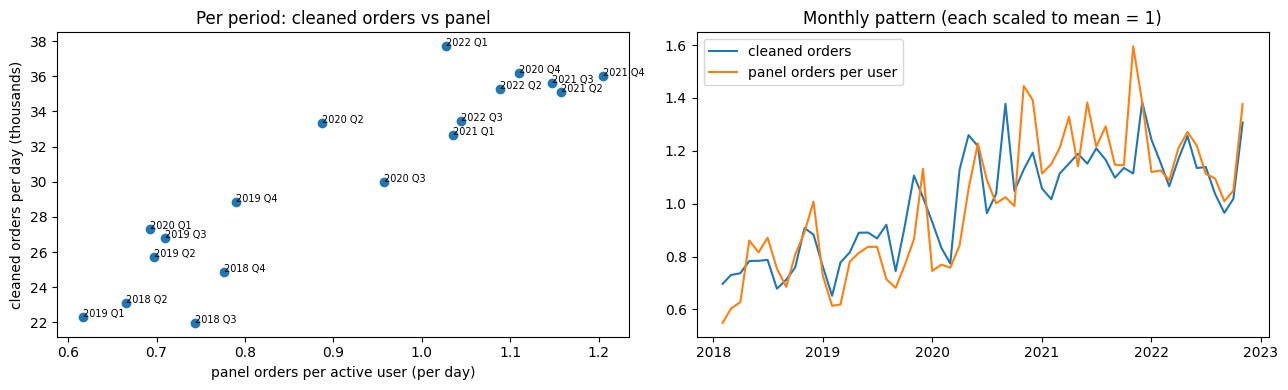

In [821]:
# Plot: cleaned orders vs panel orders, per period and per month
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: one dot per period
axes[0].scatter(check["panel_orders_per_user"], check["orders_per_day"] / 1e3)
for period, r in check.iterrows():
    axes[0].annotate(period, (r["panel_orders_per_user"], r["orders_per_day"] / 1e3), fontsize=7)
axes[0].set_xlabel("panel orders per active user (per day)")
axes[0].set_ylabel("cleaned orders per day (thousands)")
axes[0].set_title("Per period: cleaned orders vs panel")

# Right: monthly, both scaled to an average of 1 so the patterns can be compared
mon = pd.concat([monthly_orders(clean), panel_month], axis=1, keys=["orders", "panel"]).dropna().loc["2018-02":"2022-11"]
axes[1].plot(mon.index, mon["orders"] / mon["orders"].mean(), label="cleaned orders")
axes[1].plot(mon.index, mon["panel"] / mon["panel"].mean(), label="panel orders per user")
axes[1].set_title("Monthly pattern (each scaled to mean = 1)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [822]:
# Final summary of the cleaning
print(on["reason"].replace("", "kept").value_counts())
print("\nClean dates:", len(clean), "| Daily series:", cum_orders.index.min().date(), "→", cum_orders.index.max().date())

reason
kept                   472
far from trend         333
breaks monotonicity     26
gross error             25
Name: count, dtype: int64

Clean dates: 445 | Daily series: 2018-01-07 → 2022-12-30


**Step 2.7 – validation against the panel's own order counts**

**Method:** compare the cleaned order counts with an **independent** source: the transaction panel's orders per active user (`gross_orders_index ÷ weekly_active_users_index`). The panel is on a different scale, so we compare **patterns** (correlation), not sizes. Revenue is **never** used, to avoid leakage.

**Result: each step improves agreement with the panel**

| Version | Period-level correlation | Monthly correlation | Months with negative orders |
|---|---|---|---|
| Raw (no cleaning) | 0.080 | 0.005 | 2 |
| Naive rule (Step 2.1) | 0.277 | 0.129 | 0 |
| Gross errors only (Step 2.2) | 0.809 | 0.383 | 1 |
| **Full cleaning (Steps 2.2 – 2.5)** | **0.917** | **0.831** | **0** |

- The plots confirm it: per period, cleaned orders rise with panel orders, and month by month the two series follow the same ups and downs, including the seasonal peaks around Black Friday / Christmas.

**Answers**
1. **Which step mattered most?** At the **period level**, removing gross errors (Step 2.2) made the biggest jump (0.08 → 0.81). At the **monthly level**, the asymmetric trend filter and later steps made the biggest difference (0.38 → 0.83), because stale values mainly distort the timing of orders within periods.
2. **Why is the raw correlation almost zero, when the raw line looks clean?** On a chart of 34M – 89M, errors of a few million look small. But orders come from **differences** between order numbers, so one bad value (e.g. 754,349 instead of ~78M) creates swings of tens of millions of orders, including negative months. Those few huge swings drown out the real pattern.
3. **Why does the ratio fall from ~37,000 (2019) to ~30,000 (2021)?** Probably a mix of two things:
   - **Panel change:** the drop starts in **2020 Q3**, when the panel was growing fastest (COVID), so new users may have shopped online more than the average ABC customer.
   - **2021 under-counting:** in **2022**, where the order data is clean again, the ratio partly recovers (32,000 – 36,700), which suggests 2021 orders may be somewhat understated.
   These can't be fully separated with this data. Either way, it's a reminder that panel-based features can drift over time.
4. **Why never judge cleaning by revenue?** Revenue is what the model predicts. Tuning the cleaning to fit revenue would let the answer leak into the features and make the model look better than it really is.

**Boundaries that worsened after cleaning:** 28 Feb 2021 (gap 6 Feb – 17 Mar) and 31 Dec 2021 (gap 19 Dec – 3 Jan). If the orders in these gaps followed the panel's daily pattern instead of a straight line, about **52,000** and **78,000** orders would move between periods: roughly **2 – 4%** of 2021 Q1, 2021 Q4 and 2022 Q1. 28 Feb 2018 is affected by under 1%. The 2022 Q4 test period is not affected.

**Why more values were removed (384) than there were decreases (211):** 211 is the number of step-downs, not the number of bad values. Stale values often come in runs (one step down, then several low values that each look like an increase), and too-high values register their decrease on the following row. In noisy 2021, some correct values were also removed by the trend filter, which has little effect on period totals (see Steps 2.3 and 2.7).

**Final Stage 2 audit:** 856 raw rows → 25 gross errors · 333 far from trend · 26 break monotonicity → 472 rows → **445 clean dates** → a daily order series from **7 Jan 2018 to 30 Dec 2022**.

**Conclusion:** the cleaned order numbers agree well with independent panel data (0.92 per period, 0.83 per month, up from ~0 for the raw data). The main remaining uncertainty is **2021** (long gaps after cleaning, and the boundaries around it).

# Stage 3A: Transaction Data Cleaning

In [823]:
# Working copy of the transaction data, with dates as the index (makes date slicing easy)
tx = txn.copy().set_index("date").sort_index()
print("Days:", len(tx), "| from", tx.index.min().date(), "to", tx.index.max().date())

Days: 1826 | from 2018-01-01 to 2022-12-31


In [824]:
# Zero spend/orders on a day with active users = a data dropout, not a real zero → treat as missing and fill
cols = ["total_spend_index", "gross_orders_index"]
print("Before:"); display(tx.loc["2018-02-09":"2018-02-11", cols].round(3))

tx[cols] = tx[cols].where(tx[cols] > 0)                 # zeros → NaN (missing)
tx[cols] = tx[cols].interpolate(method="time")          # fill from neighbouring days

print("After:"); display(tx.loc["2018-02-09":"2018-02-11", cols].round(3))
print("Missing values left:", tx[cols].isna().sum().sum())

Before:


,total_spend_index,gross_orders_index
date,,
2018-02-09,1.172,0.636
2018-02-10,0.000,0.000
2018-02-11,0.058,0.159


After:


,total_spend_index,gross_orders_index
date,,
2018-02-09,1.172,0.636
2018-02-10,0.615,0.397
2018-02-11,0.058,0.159


Missing values left: 0


In [825]:
# How far is each day above its normal level (median of the surrounding 29 days)?
spend_vs_normal  = tx["total_spend_index"] / tx["total_spend_index"].rolling(29, center=True, min_periods=7).median()
orders_vs_normal = tx["gross_orders_index"] / tx["gross_orders_index"].rolling(29, center=True, min_periods=7).median()

big_spend = spend_vs_normal > 3                       # spend more than 3× its normal level
print("Days with spend > 3× normal:", big_spend.sum())
print("…of which orders also rose (> 1.5× normal):", (big_spend & (orders_vs_normal > 1.5)).sum())

odd = big_spend & (orders_vs_normal <= 1.5)
print("…spend spiked but orders didn't:", odd.sum())
tx[odd].assign(spend_x_normal=spend_vs_normal[odd].round(1), orders_x_normal=orders_vs_normal[odd].round(1))

Days with spend > 3× normal: 24
…of which orders also rose (> 1.5× normal): 23
…spend spiked but orders didn't: 1


,total_spend_index,gross_orders_index,weekly_active_users_index,spend_x_normal,orders_x_normal
date,,,,,
2018-02-12,3.877012,1.430843,2.221127,4.4,1.0


In [826]:
# In early 2018, gross_orders_index moves in fixed steps; each step looks like ONE order
step = 0.158983
early = tx.loc["2018-02-08":"2018-02-15", ["total_spend_index", "gross_orders_index"]].copy()
early["orders_as_count"] = (early["gross_orders_index"] / step).round(1)
early

,total_spend_index,gross_orders_index,orders_as_count
date,,,
2018-02-08,0.871279,1.430843,9.0
2018-02-09,1.171816,0.635930,4.0
2018-02-10,0.614942,0.397456,2.5
2018-02-11,0.058067,0.158983,1.0
2018-02-12,3.877012,1.430843,9.0
2018-02-13,0.392228,0.953895,6.0
2018-02-14,0.834669,1.430843,9.0
2018-02-15,0.982159,1.748808,11.0


In [827]:
# Adjust for panel size: spend and orders per active panel user
tx["spend_per_wau"]  = tx["total_spend_index"]  / tx["weekly_active_users_index"]
tx["orders_per_wau"] = tx["gross_orders_index"] / tx["weekly_active_users_index"]

tx.groupby(tx.index.year)[["spend_per_wau", "orders_per_wau"]].mean().round(3)

,spend_per_wau,orders_per_wau
date,,
2018,0.665,0.699
2019,0.694,0.717
2020,0.824,0.941
2021,1.064,1.151
2022,1.078,1.056


In [828]:
# Why AOV is computed per period, not averaged daily: daily AOV is much noisier when the panel was small
daily_aov = tx["total_spend_index"] / tx["gross_orders_index"]
print("Day-to-day variation (std) of AOV by year:")
daily_aov.groupby(daily_aov.index.year).std().round(3)

Day-to-day variation (std) of AOV by year:


,0
date,
2018,0.357
2019,0.137
2020,0.071
2021,0.075
2022,0.094


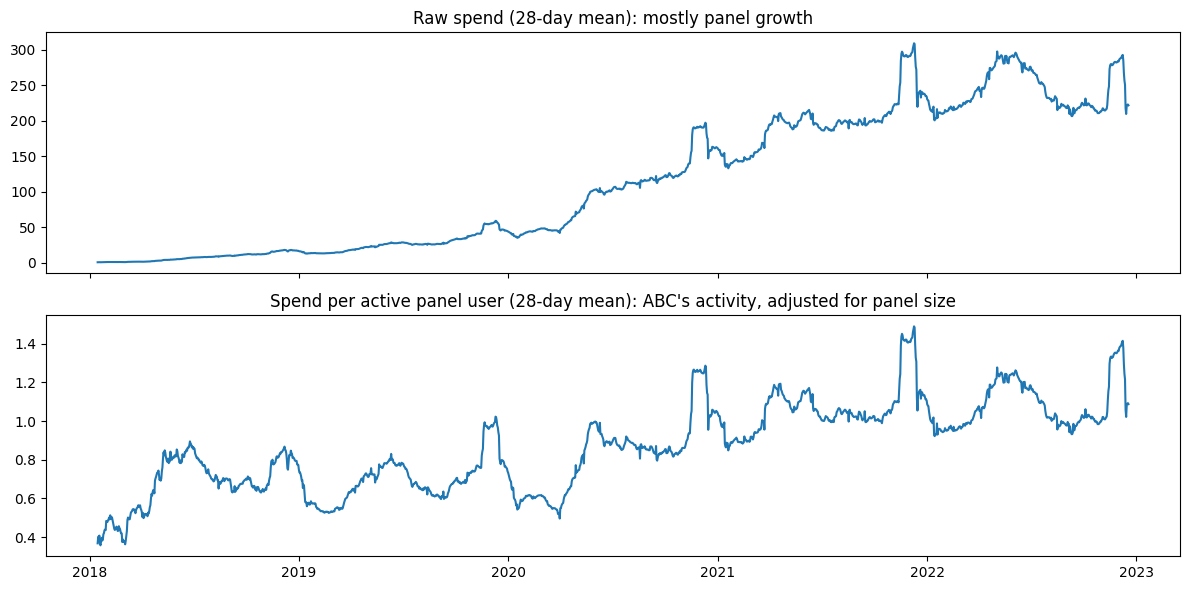

In [829]:
# Plot: raw spend vs spend per active panel user
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(tx.index, tx["total_spend_index"].rolling(28, center=True).mean())
axes[0].set_title("Raw spend (28-day mean): mostly panel growth")
axes[1].plot(tx.index, tx["spend_per_wau"].rolling(28, center=True).mean())
axes[1].set_title("Spend per active panel user (28-day mean): ABC's activity, adjusted for panel size")
plt.tight_layout()
plt.show()

**Stage 3A – transaction data cleaning**

**3A.2 – zero day:** 10 Feb 2018 had spend = 0 and orders = 0 while WAU was normal (2.21), a data dropout. It was set to missing and filled on a straight line from its neighbours: spend **0.615**, orders **0.397** (halfway between 9 and 11 Feb). No missing values remain.

**3A.3 – spikes:** 24 days had spend more than 3× their normal level (median of the surrounding 29 days).
- In **23**, orders also rose (> 1.5× normal), so they are **genuine events** (e.g. Cyber Monday 2020 – 2022). **Kept.**
- **1 odd day: 12 Feb 2018**, with spend 4.4× normal but orders normal. In early 2018, `gross_orders_index` moves in steps of 0.159, i.e. **each step is one order**: the panel saw only ~1 – 11 ABC orders a day. 12 Feb had 9 orders with unusually high spend (one or two large baskets). Genuine, but a sign of **small-panel noise**. **Kept**: removing real data would bias totals, and summing over the 59-day 2018 Q1 period dilutes it.
- (The filled-in 10 Feb shows 2.5 "orders": a filled value, not a real count.)

**3A.4 – panel-adjusted features**
- **Spend per active user** (yearly mean): 0.665 → 0.694 → 0.824 → 1.064 → 1.078.
- **Orders per active user:** 0.699 → 0.717 → 0.941 → 1.151 → 1.056.
- **AOV** will be computed **per period** (total spend ÷ total orders), not as an average of daily values: daily AOV varies far more in 2018 (std 0.357) than later (0.07 – 0.14), because a few orders a day make it jumpy.
- These yearly figures differ slightly from Stage 1 (e.g. 0.665 vs 0.73 for 2018) because Stage 1 divided yearly averages, while this averages daily ratios. The two differ when the panel changes a lot within a year.

**3A.5 – plot:** raw spend is nearly flat until 2020, then climbs steeply: the shape of **panel growth**. Spend per user shows a clear **yearly pattern** (peaks every Nov – Dec, dips each Jan – Feb), a **spring-2020 dip** and **mid-2020 jump** (COVID), a **2021 – 2022 plateau** and a **mid-2022 peak**, matching the revenue story from Stage 1.

**Answers**
1. **Why fill the zero day?** A 0 would understate 2018 Q1's spend total, and dividing by 0 orders would make AOV impossible. A missing day should be estimated, not counted as "no sales".
2. **Why is "orders rose too" a good test?** A real event means more people buying, so spend and orders rise together. Spend rising alone points to a few unusual baskets or a data issue.
3. **How much to trust 2018?** Little, at the daily level: with only ~1 – 11 ABC orders a day in the panel, single baskets swing the numbers. Period totals are more stable, but 2018 panel features remain the noisiest. Spend per user nearly doubles from early to mid-2018, far faster than revenue (+23% from 2018 Q1 to Q2), likely small-panel noise.
4. **Which plot looks like revenue?** Spend per user: it shows the same seasonality, the COVID jump and the 2022 plateau. Raw spend mostly shows the panel getting bigger.

**Stage 3A complete:** `tx` now has filled spend and orders, plus `spend_per_wau` and `orders_per_wau`, ready for Stage 4.

# Stage 3B: Checking and Preparing the Reported Data

In [830]:
# Stage 3B, Check 1: types, missing values, duplicates, order
print(reported[["period", "start_date", "end_date", "revenue_index"]].dtypes)
print("\nMissing values:", reported[["period", "start_date", "end_date", "revenue_index"]].isna().sum().sum())
print("Duplicate periods:", reported["period"].duplicated().sum())
print("Sorted by start date:", reported["start_date"].is_monotonic_increasing)
print("Every end date after its start date:", (reported["end_date"] >= reported["start_date"]).all())

period                   object
start_date       datetime64[ns]
end_date         datetime64[ns]
revenue_index           float64
dtype: object

Missing values: 0
Duplicate periods: 0
Sorted by start date: True
Every end date after its start date: True


In [831]:
# Check 2: days between the end of one period and the start of the next (should always be 1)
days_between = (reported["start_date"] - reported["end_date"].shift()).dt.days.iloc[1:]
print("Days between consecutive periods:", days_between.value_counts().to_dict())

Days between consecutive periods: {1.0: 19}


In [832]:
# Check 3: coverage of the periods vs the transaction and order data
print("Periods cover:", reported["start_date"].min().date(), "→", reported["end_date"].max().date(),
      "| total days:", reported["days"].sum())
print("Transaction data:", tx.index.min().date(), "→", tx.index.max().date(), "| days:", len(tx))
print("Clean order data:", cum_orders.index.min().date(), "→", cum_orders.index.max().date())

Periods cover: 2018-01-01 → 2022-12-31 | total days: 1826
Transaction data: 2018-01-01 → 2022-12-31 | days: 1826
Clean order data: 2018-01-07 → 2022-12-30


In [833]:
# Check 4: revenue is indexed so that 2018 Q1 = 100
base = reported.loc[reported["period"] == "2018 Q1", "revenue_index"].iloc[0]
print("2018 Q1 revenue_index:", base)
print("All revenue values positive:", (reported["revenue_index"] > 0).all())

2018 Q1 revenue_index: 100.0
All revenue values positive: True


In [834]:
# Check 5: the test period exists and is the last one
print(reported[reported["period"] == "2022 Q4"][["period", "start_date", "end_date", "days", "revenue_index"]])
print("Is it the last period?", reported["period"].iloc[-1] == "2022 Q4")

     period start_date   end_date  days  revenue_index
19  2022 Q4 2022-09-01 2022-12-31   122     512.079789
Is it the last period? True


In [835]:
# Prepared period table: one row per reporting period, with the train/test split marked
periods = reported[["period", "start_date", "end_date", "days", "revenue_index"]].copy()
periods["rev_per_day"] = periods["revenue_index"] / periods["days"]
periods["is_test"] = periods["period"] == "2022 Q4"        # train: 2018 Q1 – 2022 Q3 | test: 2022 Q4

print("Training periods:", (~periods["is_test"]).sum(), "| Test periods:", periods["is_test"].sum())
periods

Training periods: 19 | Test periods: 1


,period,start_date,end_date,days,revenue_index,rev_per_day,is_test
0,2018 Q1,2018-01-01,2018-02-28,59,100.000000,1.694915,False
1,2018 Q2,2018-03-01,2018-06-30,122,253.521127,2.078042,False
2,2018 Q3,2018-07-01,2018-08-31,62,139.788732,2.254657,False
3,2018 Q4,2018-09-01,2018-12-31,122,306.161972,2.509524,False
4,2019 Q1,2019-01-01,2019-02-28,59,117.693662,1.994808,False
5,2019 Q2,2019-03-01,2019-06-30,122,294.102113,2.410673,False
6,2019 Q3,2019-07-01,2019-08-31,62,156.514085,2.524421,False
7,2019 Q4,2019-09-01,2019-12-31,122,359.947183,2.950387,False
8,2020 Q1,2020-01-01,2020-02-29,60,148.063380,2.467723,False
9,2020 Q2,2020-03-01,2020-06-30,122,289.788732,2.375317,False


**Stage 3B – checking and preparing the reported data**

**Checks (all passed)**

| Check | Result |
|---|---|
| Types, missing values, duplicates | Dates are `datetime64`, revenue is `float64`; 0 missing; 0 duplicate periods; sorted by start date; every end date after its start date |
| Continuity | All **19** transitions are exactly **1 day** (including across the 2022 change): **no gaps, no overlaps** |
| Coverage | Periods cover **1 Jan 2018 – 31 Dec 2022 (1,826 days)**, exactly matching the transaction data. The clean order data covers **7 Jan – 30 Dec 2022**, so the first 6 days of 2018 Q1 and the last day of 2022 Q4 need a small extrapolation (Stage 4) |
| Index base | 2018 Q1 = **100.0**, as stated in the brief; all values positive |
| Test period | **2022 Q4** = 1 Sep – 31 Dec 2022 (122 days), revenue_index **512.08**, the last period |

**Preparation:** a tidy `periods` table with one row per reporting period: dates, days, `revenue_index`, `rev_per_day`, and an `is_test` flag (**19 training periods**, 2018 Q1 – 2022 Q3; **1 test period**, 2022 Q4).

**Answers**
1. **Why do gaps or overlaps matter?** Stage 4 adds up daily data over each period's dates. A gap would leave days that belong to no period (sales missing from the features); an overlap would count some days twice. Either would make the features disagree with the reported revenue.
2. **Does 512 vs 100 mean revenue per day grew 5×?** No. 2022 Q4 is 122 days long and 2018 Q1 only 59. Revenue per day grew from **1.69 to 4.20, about 2.5×**. The index compares period **totals**, so period length must always be considered.
3. **Why mark the train/test split now?** So it's decided once, before any modelling. Every later step uses `is_test`, which prevents accidentally training on, or tuning to, the test period.
4. **Why check revenue but never change it?** It's the official reported figure and the model's target. Altering it would make the model look better without making it better.

**Stage 3 complete:** all three datasets are now ready. Cleaned daily orders (`cum_orders`), cleaned daily transactions with panel-adjusted columns (`tx`), and the prepared `periods` table.

# Stage 4: Building the Feature Table

In [836]:
# Step 4.1: cumulative order number at any date, extrapolating a few days beyond the data at each edge
first_day, last_day = cum_orders.index[0], cum_orders.index[-1]
rate_start = (cum_orders.iloc[28] - cum_orders.iloc[0]) / 28        # orders/day over the first 28 days
rate_end   = (cum_orders.iloc[-1] - cum_orders.iloc[-29]) / 28      # orders/day over the last 28 days

def cum_at(date):
    """Order number at the end of `date`; extrapolates linearly before the first / after the last clean day."""
    if first_day <= date <= last_day:
        return cum_orders[date]
    if date < first_day:
        return cum_orders.iloc[0] - rate_start * (first_day - date).days
    return cum_orders.iloc[-1] + rate_end * (date - last_day).days

print(f"Rate used before the data starts: {rate_start:,.0f} orders/day")
print(f"Rate used after the data ends:    {rate_end:,.0f} orders/day")
print("Days extrapolated at the start:", (first_day - pd.Timestamp("2017-12-31")).days,
      "| at the end:", (pd.Timestamp("2022-12-31") - last_day).days)

Rate used before the data starts: 19,751 orders/day
Rate used after the data ends:    33,038 orders/day
Days extrapolated at the start: 7 | at the end: 1


In [837]:
# Step 4.2: features for one period, using only the days inside it
def period_features(start, end):
    w = tx.loc[start:end]                                               # transaction days in the period
    orders = cum_at(end) - cum_at(start - pd.Timedelta(days=1))         # orders from the order numbers
    aov = w["total_spend_index"].sum() / w["gross_orders_index"].sum()  # total spend ÷ total orders
    return {
        "orders_m":     orders / 1e6,                       # orders in the period, millions
        "spend_raw":    w["total_spend_index"].sum(),       # raw panel spend (NOT adjusted, for comparison)
        "spend_adj":    w["spend_per_wau"].sum(),           # spend per active user, summed over the period
        "orders_adj":   w["orders_per_wau"].sum(),          # panel orders per active user, summed
        "aov":          aov,                                # panel average order value
        "orders_x_aov": orders / 1e6 * aov,                 # revenue = orders × average order value
    }

feature_rows = [period_features(p["start_date"], p["end_date"]) for _, p in periods.iterrows()]
features = pd.concat([periods.reset_index(drop=True), pd.DataFrame(feature_rows)], axis=1)
features.drop(columns=["start_date", "end_date"]).round(3)

,period,days,revenue_index,rev_per_day,is_test,orders_m,spend_raw,spend_adj,orders_adj,aov,orders_x_aov
0,2018 Q1,59,100.000,1.695,False,1.260,50.102,24.440,33.223,0.749,0.944
1,2018 Q2,122,253.521,2.078,False,2.819,397.889,82.653,81.129,1.039,2.930
2,2018 Q3,62,139.789,2.255,False,1.362,535.145,46.346,46.122,1.006,1.370
3,2018 Q4,122,306.162,2.510,False,3.030,1695.200,89.337,94.762,0.938,2.844
4,2019 Q1,59,117.694,1.995,False,1.314,776.718,32.449,36.387,0.894,1.175
5,2019 Q2,122,294.102,2.411,False,3.135,2626.301,84.027,85.027,0.990,3.103
6,2019 Q3,62,156.514,2.524,False,1.662,1668.043,42.188,43.984,0.960,1.596
7,2019 Q4,122,359.947,2.950,False,3.519,5006.867,94.634,96.303,0.980,3.450
8,2020 Q1,60,148.063,2.468,False,1.637,2402.097,34.727,41.572,0.836,1.368
9,2020 Q2,122,289.789,2.375,False,4.069,9008.462,92.895,108.218,0.859,3.496


In [838]:
# Step 4.3: is the feature table complete and consistent?
print("Rows:", len(features), "| missing values:", features.isna().sum().sum())
print("Orders in all periods:", round(features["orders_m"].sum(), 3), "million")
print("Orders from first to last period end (direct):",
      round((cum_at(pd.Timestamp("2022-12-31")) - cum_at(pd.Timestamp("2017-12-31"))) / 1e6, 3), "million")
print("2018 Q1 orders that come from extrapolation:", round(rate_start * 7 / 1e6, 3), "million")

Rows: 20 | missing values: 0
Orders in all periods: 55.502 million
Orders from first to last period end (direct): 55.502 million
2018 Q1 orders that come from extrapolation: 0.138 million


In [839]:
# Step 4.4: correlation of each feature with revenue, using TRAINING periods only (the test row stays hidden)
train = features[~features["is_test"]]
feature_cols = ["orders_m", "spend_raw", "spend_adj", "orders_adj", "aov", "orders_x_aov"]
train[feature_cols + ["revenue_index"]].corr()["revenue_index"].drop("revenue_index").sort_values(ascending=False).round(3)

,revenue_index
spend_adj,0.972
orders_adj,0.970
orders_x_aov,0.939
orders_m,0.932
spend_raw,0.807
aov,0.375


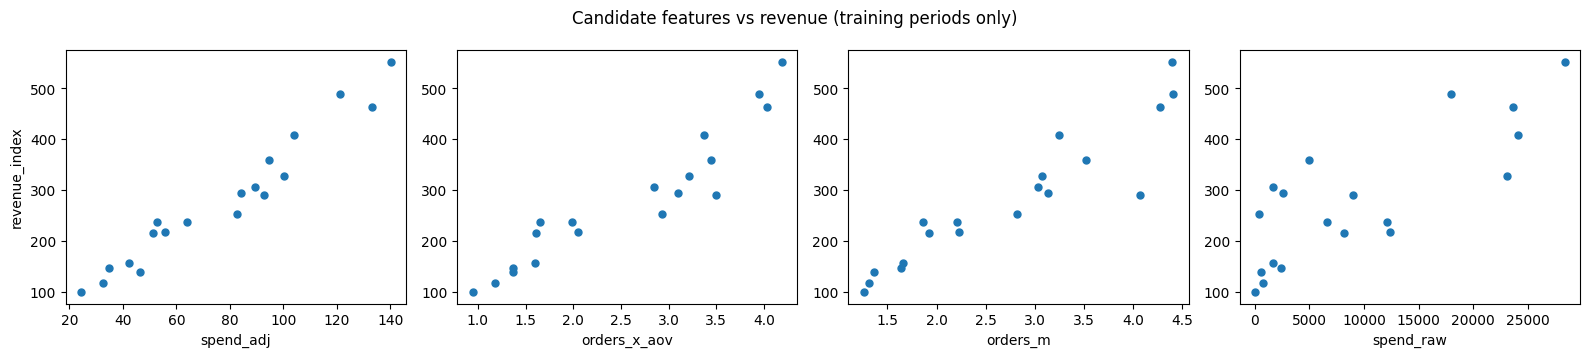

In [840]:
# Scatter: each candidate feature vs revenue, TRAINING periods only (the test period stays hidden)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col in zip(axes, ["spend_adj", "orders_x_aov", "orders_m", "spend_raw"]):
    ax.scatter(train[col], train["revenue_index"], s=25)
    ax.set_xlabel(col)
axes[0].set_ylabel("revenue_index")
plt.suptitle("Candidate features vs revenue (training periods only)")
plt.tight_layout()
plt.show()

**Stage 4 – feature table**

**Method:** for each of the 20 reporting periods, features are computed over **exactly** that period's dates, as **totals** (revenue is a period total, so longer periods have proportionally larger features and revenue).
- Order counts come from the cleaned cumulative order numbers: `order number at end date − order number on the day before the start`. The order data covers 7 Jan 2018 – 30 Dec 2022, so the edges are **extrapolated** at the nearest 28-day rate: **7 days** at the start (31 Dec 2017 → 7 Jan 2018, covering the 6 days of 2018 Q1 with no data; 19,751 orders/day) and **1 day** at the end (33,038/day).

| Feature | Meaning |
|---|---|
| `orders_m` | Orders in the period (millions), a full count from the order numbers |
| `spend_raw` | Raw panel spend (not adjusted), for comparison only |
| `spend_adj` | Spend per active panel user, summed over the period |
| `orders_adj` | Panel orders per active user, summed |
| `aov` | Panel average order value = total spend ÷ total orders (panel size cancels out) |
| `orders_x_aov` | Orders × AOV, the identity revenue = orders × average order value |

**Sanity checks:** 20 rows, 0 missing values. Orders summed over all periods (**55.502M**) equal the direct total from 31 Dec 2017 to 31 Dec 2022 (**55.502M**), so no day is missed or double-counted. **0.138M** of 2018 Q1's 1.26M orders (~11%) come from the 7 extrapolated days.

**Correlation with revenue (training periods only):**

| Feature | Correlation |
|---|---|
| `spend_adj` | **0.972** |
| `orders_adj` | 0.970 |
| `orders_x_aov` | 0.939 |
| `orders_m` | 0.932 |
| `spend_raw` | 0.807 |
| `aov` | 0.375 |

**Answers**
1. **Why sums?** Revenue is a period total, and periods range from 59 to 122 days. Totals grow with period length in the same way revenue does; averages would hide that.
2. **`spend_raw` (0.81) vs `spend_adj` (0.97):** raw spend mostly tracks the growing panel; its scatter is curved and fanned out. Dividing by active users removes panel growth, leaving a tight straight-line relationship with revenue.
3. **Why keep `aov` (0.38)?** Alone it doesn't track revenue, which is driven mainly by volume. But it explains differences that order counts miss: **2020 Q2 and 2021 Q2 had similar order counts (4.07M vs 4.28M, +5%)**, yet revenue rose from 290 to 463 (+60%), because AOV rose from 0.859 to 0.943. `orders_x_aov` captures this.
4. **Should 11% extrapolation worry us?** A little. It rests on an assumed steady rate over 7 days, and 2018 Q1 is also the weakest period for panel features (`aov` = 0.749, the lowest of all, because the panel saw only a handful of orders a day). 2018 Q1 is the least reliable training row, worth checking in Stage 5.
5. **Why can a sample (`spend_adj`) beat a full count (`orders_m`)?** An order count ignores **how much each order is worth**. Revenue = orders × value per order, and AOV ranged from 0.75 to 1.05 across training periods (0.84 – 1.05 excluding the noisy 2018 Q1). Spend measures money directly, so it captures both volume and value.

In [841]:
# Step 4.5: are the target and main features trending? (risk of spurious regression)
def stationarity(series):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return {"ADF p (low = stationary)": round(adfuller(series, maxlag=2, autolag=None)[1], 3),
                "KPSS p (low = NON-stationary)": round(kpss(series, regression="c", nlags=2)[1], 3)}

pd.DataFrame({col: stationarity(train[col]) for col in ["revenue_index", "rev_per_day", "spend_adj", "orders_x_aov"]}).T

,ADF p (low = stationary),KPSS p (low = NON-stationary)
revenue_index,0.695,0.026
rev_per_day,0.752,0.016
spend_adj,0.853,0.034
orders_x_aov,0.866,0.041


Revenue and the main features are non-stationary (they grow over time). A regression between trending series can be spurious, so after fitting (Stage 6) the residuals must be checked for stationarity. If they are stationary, the series move together in a stable way (cointegration), and the regression is valid in levels. Differencing isn’t used, because the target is revenue levels.

# Stage 5: Model Fitting and Evaluation

In [842]:
# Step 5.1: training periods (2018 Q1 – 2022 Q3) and the test period (2022 Q4)
train = features[~features["is_test"]].reset_index(drop=True)
test  = features[features["is_test"]].reset_index(drop=True)
actual_q4 = test["revenue_index"].iloc[0]
print("Training periods:", len(train), "| Test period:", test["period"].iloc[0], "| actual revenue_index:", round(actual_q4, 2))

Training periods: 19 | Test period: 2022 Q4 | actual revenue_index: 512.08


In [843]:
# Step 5.2: fit revenue_index = intercept + slope × spend_adj on the training periods
X_train = sm.add_constant(train[["spend_adj"]])       # adds a column of 1s so the model can learn an intercept
y_train = train["revenue_index"]

m2 = sm.OLS(y_train, X_train).fit()                    # OLS = ordinary least squares (the standard straight-line fit)
print(m2.summary())

                            OLS Regression Results                            
Dep. Variable:          revenue_index   R-squared:                       0.945
Model:                            OLS   Adj. R-squared:                  0.942
Method:                 Least Squares   F-statistic:                     292.6
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           3.79e-12
Time:                        00:00:42   Log-Likelihood:                -91.251
No. Observations:                  19   AIC:                             186.5
Df Residuals:                      17   BIC:                             188.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.3404     17.616      0.246      0.8

In [844]:
# Predict the unseen test period and measure the error
X_test = sm.add_constant(test[["spend_adj"]], has_constant="add")
pred_q4 = m2.predict(X_test).iloc[0]
pct_error = (pred_q4 / actual_q4 - 1) * 100
print(f"2022 Q4 predicted: {pred_q4:.1f} | actual: {actual_q4:.1f} | percentage error: {pct_error:+.1f}%")

2022 Q4 predicted: 485.7 | actual: 512.1 | percentage error: -5.1%


In [845]:
# Step 5.3: compare candidate models on the same footing
candidates = {
    "M1: orders":            ["orders_m"],
    "M2: spend_adj":         ["spend_adj"],
    "M3: orders × AOV":      ["orders_x_aov"],
    "M4: orders + spend_adj": ["orders_m", "spend_adj"],
}

results, fitted = [], {}
for name, cols in candidates.items():
    model = sm.OLS(train["revenue_index"], sm.add_constant(train[cols])).fit()
    in_sample = model.fittedvalues
    pred = model.predict(sm.add_constant(test[cols], has_constant="add")).iloc[0]
    fitted[name] = (model, in_sample, pred)
    results.append({
        "model": name,
        "R2 (in-sample)": round(model.rsquared, 3),
        "adj R2": round(model.rsquared_adj, 3),
        "in-sample MAPE %": round((abs(in_sample / train["revenue_index"] - 1)).mean() * 100, 1),
        "2022 Q4 predicted": round(pred, 1),
        "2022 Q4 error %": round((pred / actual_q4 - 1) * 100, 1),
    })

# Benchmark: same period last year (revenue per day) × this period's days, no model at all
last_year = features.loc[features["period"] == "2021 Q4", "rev_per_day"].iloc[0]
naive_pred = last_year * test["days"].iloc[0]
results.append({"model": "Benchmark: last year's rate", "R2 (in-sample)": None, "adj R2": None,
                "in-sample MAPE %": None, "2022 Q4 predicted": round(naive_pred, 1),
                "2022 Q4 error %": round((naive_pred / actual_q4 - 1) * 100, 1)})

results = pd.DataFrame(results).set_index("model")
results

,R2 (in-sample),adj R2,in-sample MAPE %,2022 Q4 predicted,2022 Q4 error %
model,,,,,
M1: orders,0.869,0.861,11.1,430.3,-16.0
M2: spend_adj,0.945,0.942,9.2,485.7,-5.1
M3: orders × AOV,0.882,0.875,11.1,469.7,-8.3
M4: orders + spend_adj,0.945,0.938,9.3,487.8,-4.8
Benchmark: last year's rate,NaN,NaN,NaN,552.4,7.9


In [846]:
# Inside M4: why doesn't adding orders help?
print(fitted["M4: orders + spend_adj"][0].summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.6817     20.928      0.319      0.754     -37.683      51.047
orders_m      -5.7175     25.530     -0.224      0.826     -59.838      48.403
spend_adj      3.7897      0.801      4.734      0.000       2.093       5.487


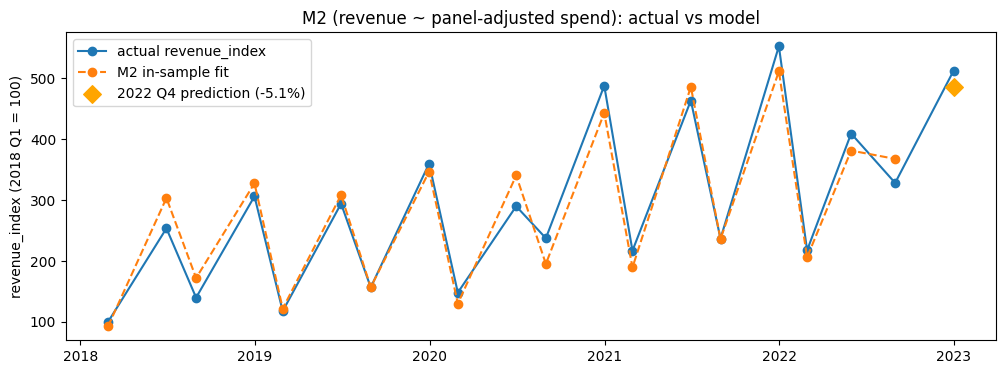

In [847]:
# Step 5.4: actual revenue vs M2's in-sample fit and its 2022 Q4 prediction
model, in_sample, pred = fitted["M2: spend_adj"]
plt.figure(figsize=(12, 4))
plt.plot(features["end_date"], features["revenue_index"], marker="o", label="actual revenue_index")
plt.plot(train["end_date"], in_sample, marker="o", linestyle="--", label="M2 in-sample fit")
plt.scatter(test["end_date"], [pred], marker="D", s=80, color="orange", zorder=3,
            label=f"2022 Q4 prediction ({(pred / actual_q4 - 1) * 100:+.1f}%)")
plt.ylabel("revenue_index (2018 Q1 = 100)")
plt.title("M2 (revenue ~ panel-adjusted spend): actual vs model")
plt.legend()
plt.show()

**Stage 5 – model fitting**

**Approach:** linear regressions (OLS) of `revenue_index` on one or two features, fitted on the **19 training periods** (2018 Q1 – 2022 Q3) and evaluated once on **2022 Q4** (actual 512.08). Models are kept simple because 19 points can't support many features without overfitting.

| Model | Type | R² | adj R² | in-sample MAPE | 2022 Q4 predicted | 2022 Q4 error |
|---|---|---|---|---|---|---|
| M1: orders | simple | 0.869 | 0.861 | 11.1% | 430.3 | −16.0% |
| **M2: spend_adj** | simple | **0.945** | **0.942** | **9.2%** | **485.7** | **−5.1%** |
| M3: orders × AOV | simple | 0.882 | 0.875 | 11.1% | 469.7 | −8.3% |
| M4: orders + spend_adj | multiple | 0.945 | 0.938 | 9.3% | 487.8 | −4.8% |
| Benchmark: last year's rate | none | — | — | — | 552.4 | +7.9% |

**M2 in detail:** revenue_index ≈ 4.34 + **3.617 × spend_adj**. The slope is highly significant (p < 0.001); the intercept is not (p = 0.81), so revenue is roughly **proportional** to panel-adjusted spend, as expected if the panel is a scaled-down copy of ABC's customers (3.6 is the scale-up factor). Durbin – Watson 1.73: no strong correlation between consecutive errors.

**Answers**
1. **R² = 0.945:** M2 explains 94.5% of the variation in revenue across the 19 training periods.
2. **Why M1 misses by −16% and M2 by −5%:** an order count ignores basket size. 2020 Q2 and 2022 Q4 both had ~4.07M orders, but revenue of 290 vs 512, because AOV rose from 0.859 to 1.037. Spend measures money directly, so it captures both volume and value.
3. **M4:** same R² as M2, but a **lower** adjusted R² (0.938 vs 0.942), and a **negative, non-significant** coefficient on orders (−5.7, p = 0.83). Orders add nothing beyond spend; the two overlap too much to separate (**multicollinearity**). Prefer the simpler M2.
4. **Why the benchmark over-predicts (+7.9%):** it assumes 2022 Q4 earns at 2021 Q4's rate, but 2022 Q4 revenue per day **fell 7.3%** year-over-year (post-COVID slowdown). Copying last year can't anticipate a change; spend data from inside the period can.
5. **Why not choose by the 2022 Q4 error alone?** One period is too noisy to rank models, and choosing by it would turn the test period into training data. Models are chosen on a walk-forward backtest instead (Stage 6).

# Stage 6: Backtesting and Model Selection

In [848]:
# Step 6.1: each candidate = a function(training_periods, period_to_predict) -> predicted revenue_index
def ols_model(cols, intercept=True, start=None):
    def predict(tr, row):
        if start:                                   # optionally ignore early periods
            tr = tr[tr["period"] >= start]
        X  = sm.add_constant(tr[cols]) if intercept else tr[cols]
        Xr = sm.add_constant(row[cols], has_constant="add") if intercept else row[cols]
        return sm.OLS(tr["revenue_index"], X).fit().predict(Xr).iloc[0]
    return predict

def last_year_rate(tr, row):
    """Benchmark: same period last year's revenue per day × this period's days."""
    year, q = row["period"].iloc[0].split()
    ly = tr[tr["period"] == f"{int(year) - 1} {q}"]
    return ly["rev_per_day"].iloc[0] * row["days"].iloc[0]

candidates = {
    "M1: orders":                      ols_model(["orders_m"]),
    "M2: spend_adj":                   ols_model(["spend_adj"]),
    "M3: orders × AOV":                ols_model(["orders_x_aov"]),
    "M4: orders + spend_adj":          ols_model(["orders_m", "spend_adj"]),
    "M2a: spend_adj, no intercept":    ols_model(["spend_adj"], intercept=False),
    "M2b: spend_adj, 2019 onwards":    ols_model(["spend_adj"], start="2019"),
    "M5: spend_adj + orders × AOV":    ols_model(["spend_adj", "orders_x_aov"]),
    "Benchmark: last year's rate":     last_year_rate,
}

In [849]:
# Extra benchmark: SARIMA on log revenue-per-day (uses only revenue's own past, no alternative data)
def sarima_rate(tr, row, order=(1, 1, 0), seasonal=(1, 0, 0, 4)):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                        # small samples trigger convergence warnings
        fit = SARIMAX(np.log(tr["rev_per_day"].to_numpy()), order=order, seasonal_order=seasonal).fit(disp=False)
    return np.exp(fit.forecast(1)[0]) * row["days"].iloc[0]    # predicted revenue per day × days

candidates["Benchmark: SARIMA (revenue history only)"] = sarima_rate

In [850]:
# Step 6.2: walk-forward backtest over the last 6 training periods
N_BACKTEST = 6
bt_rows, bt_errors = [], {}
for name, predict in candidates.items():
    errors = []
    for i in range(len(train) - N_BACKTEST, len(train)):
        pred = predict(train.iloc[:i], train.iloc[[i]])            # train only on periods BEFORE period i
        errors.append((pred / train["revenue_index"].iloc[i] - 1) * 100)
    bt_errors[name] = errors
    bt_rows.append({"model": name,
                    "backtest MAPE %": round(np.mean(np.abs(errors)), 2),
                    "average error % (bias)": round(np.mean(errors), 1),
                    "over-predictions": f"{sum(e > 0 for e in errors)}/{N_BACKTEST}"})

backtest = pd.DataFrame(bt_rows).set_index("model").sort_values("backtest MAPE %")
backtest

,backtest MAPE %,average error % (bias),over-predictions
model,,,
M2: spend_adj,6.55,-1.2,2/6
"M2b: spend_adj, 2019 onwards",6.56,1.5,3/6
"M2a: spend_adj, no intercept",6.83,-1.0,2/6
M4: orders + spend_adj,6.95,-0.8,2/6
M5: spend_adj + orders × AOV,7.94,0.5,3/6
M3: orders × AOV,10.32,-6.4,2/6
M1: orders,10.83,-10.0,1/6
Benchmark: last year's rate,11.90,-9.5,2/6
Benchmark: SARIMA (revenue history only),15.45,6.4,3/6


In [851]:
# Step 6.3: each model's error in each backtest period (positive = over-prediction)
pd.DataFrame(bt_errors, index=train["period"].iloc[-N_BACKTEST:]).round(1).T

period,2021 Q2,2021 Q3,2021 Q4,2022 Q1,2022 Q2,2022 Q3
M1: orders,-11.7,-8.3,-21.4,2.6,-18.6,-2.5
M2: spend_adj,3.0,-1.1,-10.1,-5.5,-6.6,13.1
M3: orders × AOV,-11.0,-10.0,-20.2,2.8,-8.9,9.1
M4: orders + spend_adj,3.3,-1.3,-10.3,-6.2,-5.5,15.2
"M2a: spend_adj, no intercept",4.4,-2.5,-8.5,-6.0,-6.4,13.2
"M2b: spend_adj, 2019 onwards",6.2,2.7,-8.6,-1.7,-4.8,15.2
M5: spend_adj + orders × AOV,9.6,1.8,-7.7,-8.2,-6.3,14.0
Benchmark: last year's rate,-37.5,0.3,-11.7,-0.3,-14.6,7.1
Benchmark: SARIMA (revenue history only),-7.9,37.9,-9.3,11.8,-9.9,15.8


A SARIMA model using only revenue's own history had a backtest error of **15.45%**, more than twice the chosen model's 6.55%, with a +37.9% miss on 2021 Q3 (it copied the 2020 COVID jump). Revenue's own history is a much weaker guide than spend data from inside each period.

In [852]:
# Step 6.4a: choose by backtest (training data only), THEN evaluate once on 2022 Q4
chosen = "M2: spend_adj"
final = sm.OLS(train["revenue_index"], sm.add_constant(train[["spend_adj"]])).fit()
pred_q4 = final.predict(sm.add_constant(test[["spend_adj"]], has_constant="add")).iloc[0]

print(f"Chosen model: {chosen}")
print(f"In-sample R²: {final.rsquared:.3f} (adjusted {final.rsquared_adj:.3f})")
print(f"Backtest MAPE (6 periods): {backtest.loc[chosen, 'backtest MAPE %']:.2f}%")
print(f"2022 Q4 predicted: {pred_q4:.1f} | actual: {actual_q4:.1f} | percentage error: {(pred_q4 / actual_q4 - 1) * 100:+.1f}%")

Chosen model: M2: spend_adj
In-sample R²: 0.945 (adjusted 0.942)
Backtest MAPE (6 periods): 6.55%
2022 Q4 predicted: 485.7 | actual: 512.1 | percentage error: -5.1%


In [853]:
# Step 6.4b: uncertainty and direction, what an investor would ask for
pi = final.get_prediction(sm.add_constant(test[["spend_adj"]], has_constant="add"))
for level in [0.80, 0.95]:
    lo, hi = pi.summary_frame(alpha=1 - level)[["obs_ci_lower", "obs_ci_upper"]].iloc[0]
    print(f"{level:.0%} prediction interval: {lo:.1f} – {hi:.1f}  (actual {actual_q4:.1f})")

last_year_q4 = features.loc[features["period"] == "2021 Q4", "revenue_index"].iloc[0]
print(f"Predicted change vs 2021 Q4: {(pred_q4 / last_year_q4 - 1) * 100:+.1f}% | "
      f"actual change: {(actual_q4 / last_year_q4 - 1) * 100:+.1f}%")

80% prediction interval: 440.2 – 531.3  (actual 512.1)
95% prediction interval: 413.6 – 557.8  (actual 512.1)
Predicted change vs 2021 Q4: -12.1% | actual change: -7.3%


In [854]:
# Step 6.4c: robustness. Two further ideas, tested on the same backtest (checked AFTER seeing the test result)
train_rc = train.copy()
train_rc["is_q4"] = (train_rc["period"].str[-2:] == "Q4").astype(float)
train_rc["spend_adj_per_day"] = train_rc["spend_adj"] / train_rc["days"]

def bt_mape(predict):
    errs = [(predict(train_rc.iloc[:i], train_rc.iloc[[i]]) / train_rc["revenue_index"].iloc[i] - 1) * 100
            for i in range(len(train_rc) - N_BACKTEST, len(train_rc))]
    return round(np.mean(np.abs(errs)), 2)

def per_day_model(tr, row):
    m = sm.OLS(tr["rev_per_day"], sm.add_constant(tr[["spend_adj_per_day"]])).fit()
    return m.predict(sm.add_constant(row[["spend_adj_per_day"]], has_constant="add")).iloc[0] * row["days"].iloc[0]

print("M2 (chosen):                ", bt_mape(ols_model(["spend_adj"])))
print("M2 + Q4 seasonal dummy:     ", bt_mape(ols_model(["spend_adj", "is_q4"])))
print("Revenue per day ~ spend/day:", bt_mape(per_day_model))

M2 (chosen):                 6.55
M2 + Q4 seasonal dummy:      7.54
Revenue per day ~ spend/day: 7.07


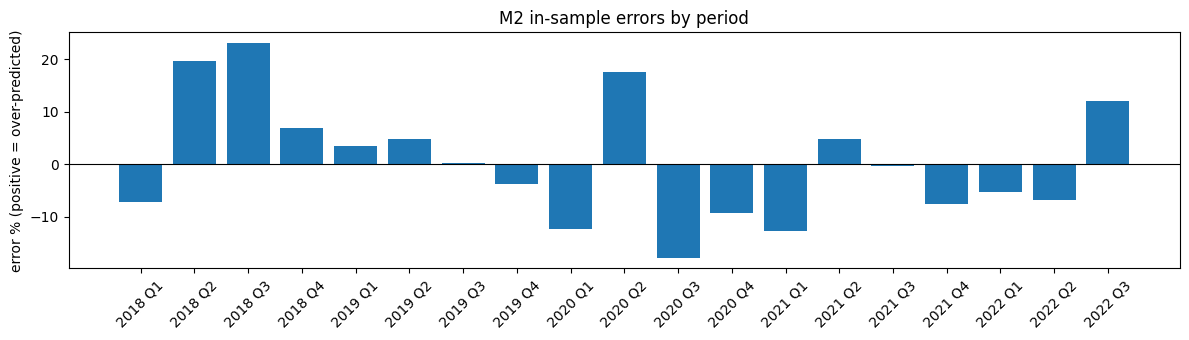

In [855]:
# Step 6.5: in-sample errors of the chosen model over time (look for patterns, not just size)
resid_pct = (final.fittedvalues / train["revenue_index"] - 1) * 100
plt.figure(figsize=(12, 3.5))
plt.bar(train["period"], resid_pct)
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=45)
plt.ylabel("error % (positive = over-predicted)")
plt.title("M2 in-sample errors by period")
plt.tight_layout()
plt.show()

In [856]:
# The same errors as numbers, so the values quoted in the notes can be checked
resid_table = pd.DataFrame({"period": train["period"], "error_%": resid_pct.round(1)})
print(resid_table.to_string(index=False))
recent = resid_table.iloc[10:18]                       # 2020 Q3 – 2022 Q2
print(f"\n2020 Q3 – 2022 Q2: {(recent['error_%'] < 0).sum()} of {len(recent)} under-predicted")

 period  error_%
2018 Q1     -7.3
2018 Q2     19.6
2018 Q3     23.0
2018 Q4      7.0
2019 Q1      3.4
2019 Q2      4.8
2019 Q3      0.3
2019 Q4     -3.7
2020 Q1    -12.2
2020 Q2     17.4
2020 Q3    -17.7
2020 Q4     -9.2
2021 Q1    -12.7
2021 Q2      4.8
2021 Q3     -0.3
2021 Q4     -7.5
2022 Q1     -5.3
2022 Q2     -6.8
2022 Q3     12.0

2020 Q3 – 2022 Q2: 7 of 8 under-predicted


In [857]:
# Step 6.6: is the relationship genuine? Compare the trending series with the model's residuals
# (uses the stationarity() function defined in Step 4.5, so there's no second definition)
pd.DataFrame({
    "revenue_index": stationarity(train["revenue_index"]),
    "spend_adj":     stationarity(train["spend_adj"]),
    "M2 residuals":  stationarity(final.resid),
}).T

,ADF p (low = stationary),KPSS p (low = NON-stationary)
revenue_index,0.695,0.026
spend_adj,0.853,0.034
M2 residuals,0.091,0.100


**Step 6.6 – stationarity of residuals:** revenue and panel-adjusted spend are both **non-stationary** (ADF p = 0.70 and 0.85; KPSS p = 0.03), so a regression between them could be spurious. But M2's **residuals are stationary** (KPSS p ≥ 0.10; ADF p = 0.091): revenue and panel spend move together in a stable way (**cointegration**), so the regression is valid in levels. Durbin – Watson is 1.73, so there is no strong correlation between consecutive errors.

**Caveats:** with 19 points these tests have low power, and residual-based tests strictly need stricter (Engle – Granger) critical values, so this is supporting evidence. The backtest (6.55% vs 11.90% for the benchmark) is the stronger confirmation.

**Stage 6 – backtest and model selection**

**Method:** walk-forward (expanding-window) backtest over the last **6 training periods** (2021 Q2 – 2022 Q3). For each, models are trained only on earlier periods and predict it, giving 6 honest out-of-sample errors per model without touching 2022 Q4.

| Model | Backtest MAPE | Bias | Over-predictions |
|---|---|---|---|
| **M2: spend_adj** | **6.55%** | −1.2% | 2/6 |
| M2b: spend_adj, 2019 onwards | 6.56% | +1.5% | 3/6 |
| M2a: spend_adj, no intercept | 6.83% | −1.0% | 2/6 |
| M4: orders + spend_adj | 6.95% | −0.8% | 2/6 |
| M5: spend_adj + orders × AOV | 7.94% | +0.5% | 3/6 |
| M3: orders × AOV | 10.32% | −6.4% | 2/6 |
| M1: orders | 10.83% | −10.0% | 1/6 |
| Benchmark: last year's rate | 11.90% | −9.5% | 2/6 |
| Benchmark: SARIMA (revenue history only) | 15.45% | +6.4% | 3/6 |

**Chosen model: M2 (revenue ~ panel-adjusted spend).**
- **In-sample R² = 0.945** (adjusted 0.942)
- **Backtest MAPE = 6.55%**, about half the naive benchmark (11.90%) and well below SARIMA (15.45%)
- **2022 Q4: predicted 485.7 vs actual 512.1 → −5.1%** (under-prediction), evaluated once, after choosing the model
- **Uncertainty:** 80% prediction interval **440 – 531**, 95% interval **414 – 558**. The actual (512.1) falls inside both.
- **Direction:** predicted change vs 2021 Q4 **−12.1%**, actual **−7.3%**: the decline was called correctly, but its size was overstated.

**Answers**
1. **Is the win clear?** M2 and M2b are essentially tied (6.55% vs 6.56%). M2 is preferred because it is **simpler** and uses **all** the data. The difference is far too small to justify dropping a year of training data.
2. **Did any improvement help?** No variant beat plain M2 (no intercept, dropping 2018, adding orders × AOV). That suggests M2 already captures the main signal; the extra complexity only adds noise.
3. **M1's bias (−10%, 5 of 6 under-predicted):** AOV rose through 2021 – 2022 (to ~1.04 in 2022), so the same number of orders brought more revenue. An orders-only model can't see that, so it keeps under-predicting.
4. **The benchmark's −37.5% on 2021 Q2:** it copies 2020 Q2's revenue rate, the COVID lockdown period, when revenue per day dipped. 2021 Q2 was back at normal (higher) levels.
5. **Is −5.1% on 2022 Q4 typical?** Yes. M2's backtest errors range from −10.1% to +13.1% (average size 6.55%), so −5.1% is a normal error for this model, neither lucky nor unlucky.
6. **Residual pattern:** 2018 Q2 – Q3 are over-predicted by ~20 – 23% (small 2018 panel; spend per user jumped faster than revenue). 2020 swings both ways (Q2 +17.4%, Q3 −17.7%) as COVID temporarily broke the usual relationship. From 2020 Q3 to 2022 Q2, **7 of 8 periods are under-predicted** (one, 2021 Q3, is ≈ 0 at −0.3%): a **mild tendency to under-predict recent periods**, consistent with the −5.1% on 2022 Q4 and with revenue per unit of panel spend drifting up over time (likely panel composition). M2b, which targets this, did not improve the backtest, so the drift is small and not consistent enough to model reliably.

**Robustness (checked after seeing the test result, so reported but not adopted):** adding a Q4 seasonal dummy (backtest MAPE 7.54%) and modelling revenue per day (7.07%) were both worse than M2 (6.55%).

**Look-ahead caveat:** the order-number cleaning uses centred windows (rolling medians, LOWESS) that see data after each date, so the backtests of the order-based models (M1, M3, M4, M5) are slightly optimistic. The chosen model (M2) does not use order numbers and is essentially unaffected.

**Limitations:** only 19 training periods; the panel-to-revenue ratio drifts over time (3.0 – 4.5), so the model would need regular recalibration; 2021 order counts are the least certain (Stage 2).

# Stage 7: Summary and Conclusions

## 7.1 Objective and data

**Objective:** predict ABC-Retail's `revenue_index` for each reporting period from alternative data; train on periods up to 2022 Q3, evaluate on 2022 Q4, and report in-sample R² and the out-of-sample percentage error.

| Dataset | What it is | Main issues found |
|---|---|---|
| **Reported data** | 20 periods (2018 Q1 – 2022 Q4) with `revenue_index` (2018 Q1 = 100) | Periods are 59 – 122 days, not calendar quarters; June moved from Q2 to Q3 in 2022 |
| **Order numbers** | Sequential order IDs on some dates (856 rows) | Only 41% of days observed; 102 dates with conflicting values; 211 impossible decreases; near-zero and stale values |
| **Transaction panel** | Daily spend, orders and weekly active users (WAU), indexed to 20 May 2020 | Panel grew 22× (WAU); noisy 2018 data (tiny panel); one zero day |

## 7.2 Approach

1. **Explore** all three datasets and list every issue with evidence and a severity (Stage 1).
2. **Clean the order numbers** in layers, labelling rather than deleting rows (Stage 2):
   - remove gross errors (> 10% from the median of 21 neighbours),
   - remove stale values with an **asymmetric** LOWESS trend filter (stricter below the trend, because errors are mostly low),
   - enforce "order numbers only go up" (longest increasing subsequence),
   - keep one value per date, and fill missing days by interpolating the **cumulative** order number.
   - **Validated against the panel's own order counts, never revenue** (period-level correlation 0.08 raw → 0.92 cleaned).
3. **Clean the transaction data:** fill the one zero day, keep genuine spikes (Cyber Monday), and **normalise spend and orders by WAU** (Stage 3A). Check the reported periods are continuous, with no gaps or overlaps (Stage 3B).
4. **Build features over each period's exact dates** (59 – 122 days), as totals: orders, panel-adjusted spend, panel orders, AOV, orders × AOV (Stage 4).
5. **Fit simple regressions** (1 – 2 features; only 19 training points) and **choose the model on a walk-forward backtest** over the last 6 training periods, against a naive and a SARIMA benchmark (Stages 5 – 6).

## 7.3a Key decisions and why

| Decision | Why | Evidence |
|---|---|---|
| Normalise panel spend by WAU | The panel grew 22× while revenue grew 1.8×; raw spend mostly measures panel growth | Correlation with revenue: raw 0.81 → adjusted 0.97 |
| Asymmetric cleaning of order numbers | Bad values were mostly **below** the true series (stale values) | Plots; agreement with panel orders rose to 0.92 (period) / 0.83 (monthly) |
| Interpolate the **cumulative** order number, not daily orders | Keeps period totals exact when boundaries are observed | Orders summed over periods = direct total (55.502M) |
| Features over **exact period dates** | Periods are irregular and changed in 2022 | Continuity check: all 19 transitions exactly 1 day |
| **Simple models** only | 19 training points; flexible models would overfit | M4 (two features) had a lower adjusted R² and a meaningless coefficient |
| Select on **backtest**, not on 2022 Q4 | One test point is too noisy and would leak into model choice | SARIMA, using revenue history only, had a 15.45% backtest error vs 6.55% for M2 |

## 7.3b How the brief's tips were addressed

| Tip in the brief | How it was handled |
|---|---|
| **Daily data must be aggregated to the reporting periods** | Every feature is summed over each period's **exact** start and end dates (inclusive), not calendar quarters (Stage 4). Continuity was checked first: all 19 period transitions are exactly 1 day (Stage 3B). |
| **Do the different period lengths matter?** | **Yes.** Periods range from 59 to 122 days, and the 2022 boundaries moved (June shifted from Q2 to Q3). A 122-day period naturally has about twice the revenue of a 59-day one, so features are **totals** over the same days as revenue, which keeps them on the same footing. Revenue **per day** was used to compare periods and years (Stage 1), and a per-day model was tested as an alternative (backtest 7.07% vs 6.55%: not better). |
| **Only 19 training points, so avoid overfitting** | Models limited to 1 – 2 features; flexible models (random forests, neural networks) not used. Adding a second feature (M4) lowered adjusted R² and gave a meaningless coefficient. Model chosen on a walk-forward backtest, not on in-sample fit. |
| **Dropping early observations is allowed** | Tested: training from 2019 onwards (M2b) gave a backtest error of 6.56% vs 6.55% with all data, so all data was kept (simpler, more data). The noisy 2018 panel is noted as a limitation. |
| **Transformations and interactions** | Per-user normalisation (spend ÷ WAU); an interaction feature, orders × AOV, from the identity revenue = orders × average order value; a per-day model; log revenue per day (SARIMA benchmark). |
| **Normalise spend for panel size** | `total_spend_index ÷ weekly_active_users_index`, summed over each period. The panel grew 22× while revenue grew 1.8×; normalising raised the correlation with revenue from 0.81 to 0.97. WAU covers the whole panel, not just ABC shoppers, so changes in panel composition remain a caveat (7.5). |
| **Order numbers are unclean and have missing dates** | Layered cleaning with an audit trail, then interpolation of the **cumulative** order number, so period totals stay exact. Validated against the panel's own order counts (0.08 raw → 0.92 cleaned), never against revenue (Stage 2). |

## 7.4 Results

**Chosen model (M2):** `revenue_index ≈ 4.34 + 3.617 × spend_adj`. The intercept is not significant (p = 0.81), so revenue is roughly **proportional** to panel-adjusted spend, as expected if the panel is a scaled-down copy of ABC's customers.

| | M2 (chosen) | Orders only (M1) | Orders × AOV (M3) | Naive benchmark | SARIMA |
|---|---|---|---|---|---|
| In-sample R² | **0.945** | 0.869 | 0.882 | — | — |
| Backtest MAPE (6 periods) | **6.55%** | 10.83% | 10.32% | 11.90% | 15.45% |
| 2022 Q4 error | **−5.1%** | −16.0% | −8.3% | +7.9% | — |

**2022 Q4 (test period):** predicted **485.7** vs actual **512.1** (**−5.1%**); 80% interval 440 – 531, 95% interval 414 – 558. The actual falls inside both. Predicted change vs 2021 Q4: −12.1% (actual −7.3%), so the decline was called correctly but overstated. The −5.1% is typical for this model: its backtest errors ranged from −10.1% to +13.1%.

**Diagnostics:** residuals are stationary (ADF p = 0.091, KPSS p ≥ 0.10), so revenue and panel spend are cointegrated and the regression is not spurious; Durbin – Watson 1.73 (no strong autocorrelation).

## 7.5 Limitations and next steps

**Limitations**
- **Small sample:** 19 training periods; all metrics carry wide uncertainty, and a single test period cannot rank models.
- **Panel drift:** revenue per unit of panel spend ranged from 3.0 to 4.5 across periods. The model under-predicted 7 of the 8 periods from 2020 Q3 to 2022 Q2, consistent with drift in panel composition.
- **Noisy 2018 panel:** only ~1 – 11 ABC orders a day in the panel in early 2018; 2018 Q2 – Q3 are over-predicted by ~20%.
- **2021 order counts are the least certain:** heavy noise led to long gaps after cleaning (up to 89 days). This affects the order-based models, not the chosen one.
- **Look-ahead in cleaning:** centred windows see later data, so the order-based backtests are slightly optimistic. M2 does not use order numbers.

**Next steps (in production)**
- **Recalibrate regularly** (e.g. a rolling window) and monitor panel composition, especially after the 2022 WAU decline.
- Model **year-over-year growth** of panel spend, which cancels out slow panel drift.
- Compare predictions with **consensus estimates**: for an investor, the value lies in the surprise versus consensus, delivered weeks before the company reports.
- Re-test as new periods are reported; with more history, seasonal terms or combining spend with orders × AOV may start to help.

## 7.6 Conclusion

Panel-adjusted transaction spend predicts ABC-Retail's reported revenue well: **R² = 0.945** in sample, a **6.55%** walk-forward backtest error (half that of a naive benchmark), and **−5.1%** on the held-out 2022 Q4, with the actual inside the 80% prediction interval. The main value came from **data work**: normalising for panel growth, cleaning the order numbers using how they are generated, and validating against independent data. Model complexity added nothing.